# Phase 11 Part 1B — CLEAN-v3 Four-Model Baseline Failure Analysis

**Model:** Gemini 3.1 Pro High · **Date:** 2026-09-21
**Manifest:** `phase4_v3` · **Taxonomy:** `kub_size_clean_v3_v1` · **Split:** KUB VAL (280)

Analyses all four frozen clean-v3 baselines: **UNet, Attention U-Net, UNet++, DeepLabV3+**.

---

> **No winner. No rank. No reference model. No significance testing.**
> These are single-seed development VAL failure analyses.
>
> UNet++ appears as `HISTORICAL_REPLICATION_ANALYSIS_ANCHOR` only — that is a replication
> role for historically anchored strata, **not** a winner / best-model / Phase-12 decision.
>
> TEST is **LOCKED** (0 reads). Phase 12 is **NOT** started.


## 2. Scope and Governance

| Rule | Status |
|---|---|
| Training epochs / optimizer steps / checkpoint writes | **0** |
| TEST image/mask/content reads · metrics · visualizations | **0** |
| Winner declared | **NO** |
| Phase-12 reference model selected | **NO** (`SUPERVISOR_DECISION_REQUIRED`) |
| Statistical significance testing | **NOT PERFORMED** |
| New unauthorized thresholds | **0** |
| Phase 12 started | **NO** |


## 3. Supervisor-Frozen Failure Protocol

The protocol was frozen **before** any current failure inspection
(`reports/audits/phase11_clean_v3_failure_protocol_frozen.json`).


In [1]:
import json
import json
from pathlib import Path as _P
ROOT = _P(r'D:\Softfors\jup')
AUD = ROOT/'reports'/'audits'
fz = json.loads((AUD/'phase11_clean_v3_failure_protocol_frozen.json').read_text(encoding='utf-8'))
print('status:', fz['status'], '| recorded before inspection:', fz['recorded_before_current_failure_inspection'])
for k in ['1A_low_dice_stratum','1B_historical_replication_anchor','1C_shared_failure',
          '1D_architecture_disagreement','1E_hd95_stratum','1F_fp_burden',
          '1G_pixel_error_extension','1H_multicomponent','1I_phase12_reference_model']:
    v = fz['frozen_protocol'][k]
    print(f'\n[{k}]')
    for kk, vv in v.items():
        print(f'   {kk}: {vv}')


status: SUPERVISOR_FROZEN | recorded before inspection: True

[1A_low_dice_stratum]
   method: bottom decile of Dice, computed per model from all 280 clean-v3 KUB VAL cases
   quantile_implementation: np.quantile(values, 0.10) default 'linear' interpolation, float64 (matches historical method)
   definition: low_dice_model = dice <= model_specific_clean_v3_q10
   ties: ties at cutoff remain INCLUDED
   historical_cutoff_reused: False
   historical_v2_value_provenance_only: 0.5461063385009766
   note: do NOT force exactly 28 cases if ties produce more

[1B_historical_replication_anchor]
   anchor_model: UNet++
   anchor_role: HISTORICAL_REPLICATION_ANALYSIS_ANCHOR
   is_not: ['winner', 'best model', 'superiority claim', 'Phase-12 reference-model decision']
   scope: replication of historical single-model failure strata ONLY
   main_analysis: all four models remain in the main clean-v3 failure analysis

[1C_shared_failure]
   primary_definition: ALL_FOUR_LOW
   rule: UNet low AND Attenti

## 4. Phase-10 Frozen Inputs


In [2]:
import sys, pandas as pd, numpy as np, json
from pathlib import Path
from PIL import Image
pd.set_option('display.max_rows', None); pd.set_option('display.max_columns', None)
pd.set_option('display.width', None); pd.set_option('display.max_colwidth', None)
PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT/'notebooks'/'phasewise'/'phase_11_failure_analysis'/'code'))
import phase11_failure_analysis as fa
import matplotlib.pyplot as plt
%matplotlib inline

per_model = pd.read_csv(fa.TABLES/'phase11_clean_v3_per_model_case_failure_metrics.csv')
cuts     = pd.read_csv(fa.TABLES/'phase11_clean_v3_low_dice_decile_cutoffs.csv')
anchor   = pd.read_csv(fa.TABLES/'phase11_clean_v3_unetpp_failure_decile_cutoffs.csv')
paired   = pd.read_csv(fa.TABLES/'phase11_clean_v3_paired_case_failure_summary.csv')
disag    = pd.read_csv(fa.TABLES/'phase11_clean_v3_architecture_disagreement.csv')
top4     = pd.read_csv(fa.TABLES/'phase11_clean_v3_top_disagreement_cases.csv')
cohort   = pd.read_csv(fa.TABLES/'phase11_clean_v3_hard_case_selection.csv')
summary  = pd.read_csv(fa.TABLES/'phase11_clean_v3_failure_summary_by_model.csv')

print('per-model rows:', len(per_model), '| paired rows:', len(paired), '| disagreement rows:', len(disag))
print()
print(summary[['model','mean_dice','median_dice','empty_predictions','object_recall',
               'missed_components','fp_eval_components']].to_string(index=False))


per-model rows: 1120 | paired rows: 280 | disagreement rows: 280

          model  mean_dice  median_dice  empty_predictions  object_recall  missed_components  fp_eval_components
           UNet   0.740613     0.823483                  8       0.896341                 34                2844
Attention U-Net   0.752513     0.822225                  3       0.923780                 25                2819
         UNet++   0.764160     0.836517                  6       0.914634                 28                 463
     DeepLabV3+   0.750914     0.838486                 11       0.881098                 39                  66


## 5. KUB-Only VAL Integrity


In [3]:
frame = fa.kub_val_frame()
print('KUB VAL rows   :', len(frame))
print('Categories     :', frame['category'].value_counts().to_dict())
print('Acquisition    :', frame['acquisition_type'].value_counts().to_dict())
assert len(frame)==280
assert frame['category'].value_counts().to_dict()=={'Bladder_Stone':144,'Kidney_Stone':112,'Ureteric_Stone':24}
assert frame['acquisition_type'].value_counts().to_dict()=={'ROI':177,'FULL_FIELD':103}
assert set(per_model['acquisition_type'])<= {'ROI','FULL_FIELD'}
print('\nKUB-ONLY VAL GATE - PASS (280 = 144+112+24; ROI 177 + FULL_FIELD 103)')
print('No TEST rows present.')


KUB VAL rows   : 280
Categories     : {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}
Acquisition    : {'ROI': 177, 'FULL_FIELD': 103}

KUB-ONLY VAL GATE - PASS (280 = 144+112+24; ROI 177 + FULL_FIELD 103)
No TEST rows present.


## 6. Prediction Reproduction Gate

Aggregate macro Dice must reproduce the frozen Phase-10 authoritative values within
**1e-4**. (Recomputed with canonical loader, batch 4, AMP, `round()` resize math.)


In [4]:
gate = pd.DataFrame([
 {'model': fa.DISPLAY[k], 'recomputed': float(per_model[per_model.model==k]['dice'].mean()),
  'authoritative': fa.AUTHORITATIVE[k],
  'abs_diff': abs(float(per_model[per_model.model==k]['dice'].mean()) - fa.AUTHORITATIVE[k])}
 for k in fa.MODELS])
gate['pass_1e-4'] = gate['abs_diff'] < fa.MATERIAL_TOL
display(gate)
assert gate['pass_1e-4'].all(), 'CHECK_REQUIRED: aggregate reproduction exceeded 1e-4'
print('\nREPRODUCTION GATE - PASS (all models within 1e-4)')
print('Authoritative Phase-10 values retained unchanged.')


,model,recomputed,authoritative,abs_diff,pass_1e-4
0,UNet,0.740613,0.740613,2.607532e-08,True
1,Attention U-Net,0.752513,0.752513,4.514320e-10,True
2,UNet++,0.764160,0.764160,7.507387e-10,True
3,DeepLabV3+,0.750914,0.750914,3.175408e-10,True



REPRODUCTION GATE - PASS (all models within 1e-4)
Authoritative Phase-10 values retained unchanged.


## 7. Model-Specific Clean-v3 Decile Cutoffs

Bottom Dice decile per model, `np.quantile(values, 0.10)` (default linear, float64).
**Ties included**; counts need not be exactly 28.


In [5]:
display(cuts[['model','n','q10_cutoff','count_le_cutoff','prevalence','tie_count_at_cutoff']])
print()
print('Historical v2 cutoff 0.5461063385009766 is provenance only and was NOT reused.')


,model,n,q10_cutoff,count_le_cutoff,prevalence,tie_count_at_cutoff
0,UNet,280,0.469394,28,0.1,0
1,Attention U-Net,280,0.536024,28,0.1,0
2,UNet++,280,0.561806,28,0.1,0
3,DeepLabV3+,280,0.378429,28,0.1,0



Historical v2 cutoff 0.5461063385009766 is provenance only and was NOT reused.


## 8. Historical UNet++ Replication Cutoffs

UNet++ anchored strata (HD95/FP) — `HISTORICAL_REPLICATION_ANALYSIS_ANCHOR` only.


In [6]:
for c in anchor.columns:
    print(f'  {c}: {anchor.loc[0, c]}')
print()
print('v2 values shown in *_provenance columns are HISTORICAL only and were not applied.')


  anchor_model: UNet++
  anchor_role: HISTORICAL_REPLICATION_ANALYSIS_ANCHOR
  n_cases: 280
  clean_v3_low_dice_q10: 0.5618055568014564
  low_dice_count: 28
  hd95_valid_n: 274
  hd95_invalid_n: 6
  clean_v3_hd95_q90_valid: 85.24095485204775
  high_hd95_count: 28
  clean_v3_fp_q90: 5.0
  high_fp_count: 31
  historical_v2_dice_q10_provenance: 0.5461063385009766
  historical_v2_hd95_q90_provenance: 83.07246563841615
  historical_v2_fp_cutoff_provenance: 4
  note: clean-v3 cutoffs recomputed; v2 values are provenance columns only

v2 values shown in *_provenance columns are HISTORICAL only and were not applied.


## 9. Empty-Prediction Analysis


In [7]:
emp = pd.read_csv(fa.TABLES/'phase11_clean_v3_empty_prediction_analysis.csv')
display(emp)
print()
print('Cases by number of models with empty prediction:')
print(paired['empty_prediction_model_count'].value_counts().sort_index().to_string())
print()
print('Empty predictions are concentrated in FULL_FIELD (tiny targets); ROI almost never empty.')


,model_display,acquisition_type,sum,mean
0,Attention U-Net,FULL_FIELD,3,0.029126
1,Attention U-Net,ROI,0,0.000000
2,DeepLabV3+,FULL_FIELD,11,0.106796
3,DeepLabV3+,ROI,0,0.000000
4,UNet,FULL_FIELD,8,0.077670
5,UNet,ROI,0,0.000000
6,UNet++,FULL_FIELD,5,0.048544
7,UNet++,ROI,1,0.005650



Cases by number of models with empty prediction:
empty_prediction_model_count
0    261
1     15
3      3
4      1

Empty predictions are concentrated in FULL_FIELD (tiny targets); ROI almost never empty.


## 10–11. Object-Detection Analysis (and FULL_FIELD size strata)

8-connectivity, `>= 1 px` overlap. Detection measured in **evaluation-512 space**;
size strata from **original native FULL_FIELD** space (`kub_size_clean_v3_v1`).


In [8]:
display(summary[['model','gt_eval_components','detected_components','missed_components',
                 'object_recall','fp_eval_components']])
print()
size = pd.read_csv(fa.TABLES/'phase11_clean_v3_fullfield_size_stratum_object_analysis.csv')
display(size[['model','stratum','GT_components','COMPLETE_DETECTION','PARTIAL_DETECTION','COMPLETE_MISS']])
print()
print('ROI components are ROI_NOT_PRIMARY_BINNED - never size-binned.')


,model,gt_eval_components,detected_components,missed_components,object_recall,fp_eval_components
0,UNet,328,294,34,0.896341,2844
1,Attention U-Net,328,303,25,0.923780,2819
2,UNet++,328,300,28,0.914634,463
3,DeepLabV3+,328,289,39,0.881098,66


,model,stratum,GT_components,COMPLETE_DETECTION,PARTIAL_DETECTION,COMPLETE_MISS
0,UNet,LARGE,193,12,3,1
1,UNet,MEDIUM,36,30,5,1
2,UNet,SMALL,28,18,6,4
3,UNet,TINY,72,43,18,11
4,Attention U-Net,LARGE,193,14,1,1
5,Attention U-Net,MEDIUM,36,31,4,1
6,Attention U-Net,SMALL,28,20,5,3
7,Attention U-Net,TINY,72,50,14,8
8,UNet++,LARGE,193,12,3,1
9,UNet++,MEDIUM,36,29,4,3



ROI components are ROI_NOT_PRIMARY_BINNED - never size-binned.


saved phase11_clean_v3_object_detection.png


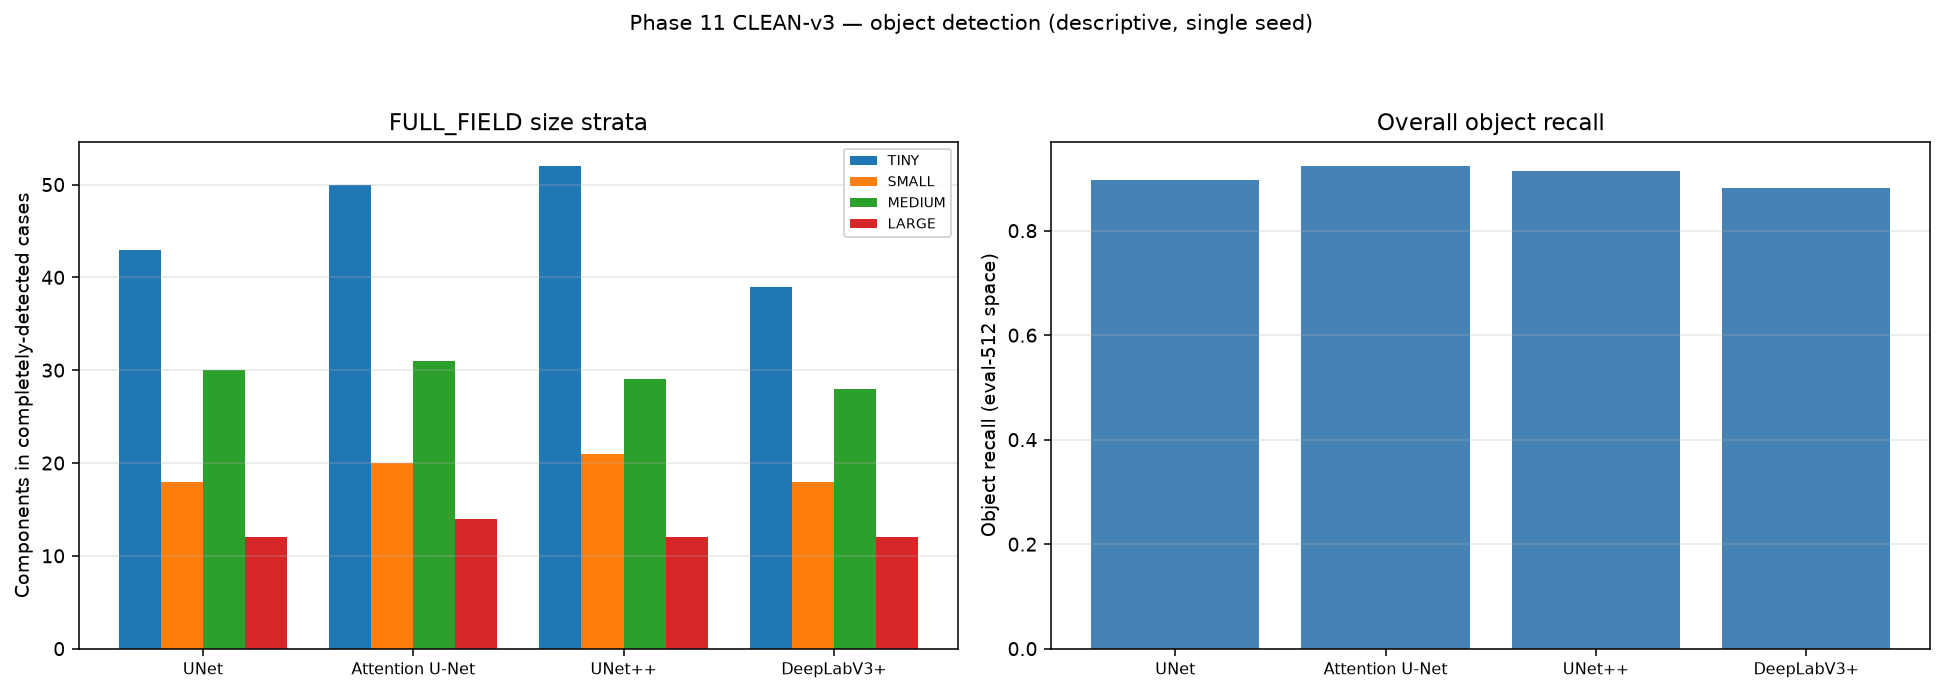

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Phase 11 CLEAN-v3 — object detection (descriptive, single seed)', fontsize=11)
ax = axes[0]
w = 0.2; x = np.arange(len(fa.MODELS))
for i, strat in enumerate(['TINY','SMALL','MEDIUM','LARGE']):
    s = size[size.stratum==strat].set_index('model')
    vals = [float(s.loc[fa.DISPLAY[k],'COMPLETE_DETECTION']) for k in fa.MODELS]
    ax.bar(x + (i-1.5)*w, vals, w, label=strat)
ax.set_xticks(x); ax.set_xticklabels([fa.DISPLAY[k] for k in fa.MODELS], fontsize=8)
ax.set_ylabel('Components in completely-detected cases'); ax.set_title('FULL_FIELD size strata')
ax.legend(fontsize=7); ax.grid(True, alpha=.3, axis='y')

ax = axes[1]
ax.bar([fa.DISPLAY[k] for k in fa.MODELS], summary['object_recall'], color='steelblue')
ax.set_ylabel('Object recall (eval-512 space)'); ax.set_title('Overall object recall')
ax.tick_params(axis='x', labelsize=8); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(rect=[0,0,1,0.93])
p1 = fa.FIGURES/'phase11_clean_v3_object_detection.png'; fig.savefig(p1, dpi=140, bbox_inches='tight'); plt.close(fig)
print('saved', p1.name)
from IPython.display import Image as IPImage
display(IPImage(filename=str(p1)))


## 12. Multi-Component Analysis (8-connectivity)


,model,multicomponent_cases,COMPLETE_DETECTION,PARTIAL_DETECTION,COMPLETE_MISS,connectivity
0,UNet,49,30,16,3,8
1,Attention U-Net,49,33,12,4,8
2,UNet++,49,33,11,5,8
3,DeepLabV3+,49,27,16,6,8



Membership: ORIGINAL_NATIVE (8-conn component count > 1).
Detection : EVALUATION_512 (8-conn, >=1 px overlap).


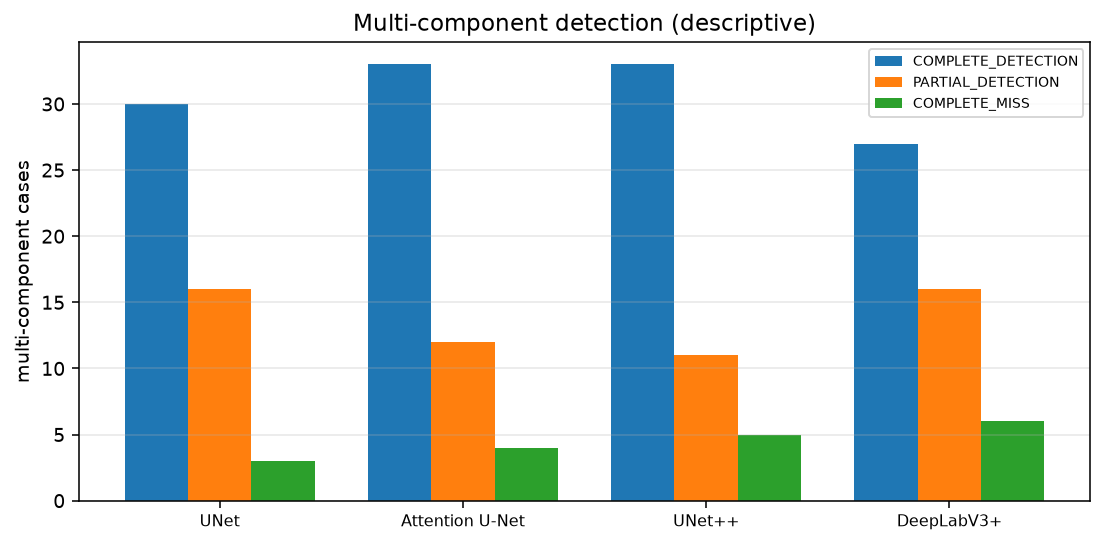

In [10]:
mc = pd.read_csv(fa.TABLES/'phase11_clean_v3_multicomponent_analysis.csv')
display(mc[['model','multicomponent_cases','COMPLETE_DETECTION','PARTIAL_DETECTION','COMPLETE_MISS','connectivity']])
print()
print('Membership: ORIGINAL_NATIVE (8-conn component count > 1).')
print('Detection : EVALUATION_512 (8-conn, >=1 px overlap).')
fig, ax = plt.subplots(figsize=(8,4))
idx = np.arange(len(mc)); w=0.26
for i, c in enumerate(['COMPLETE_DETECTION','PARTIAL_DETECTION','COMPLETE_MISS']):
    ax.bar(idx + (i-1)*w, mc[c], w, label=c)
ax.set_xticks(idx); ax.set_xticklabels(mc['model'], fontsize=8)
ax.set_ylabel('multi-component cases'); ax.set_title('Multi-component detection (descriptive)')
ax.legend(fontsize=7); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout()
p2 = fa.FIGURES/'phase11_clean_v3_multicomponent.png'; fig.savefig(p2, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p2)))


## 13. Boundary / HD95 Analysis (validity-aware)


In [11]:
bd = pd.read_csv(fa.TABLES/'phase11_clean_v3_boundary_hd95_summary.csv')
display(bd[['model_display','n_total','n_valid','n_invalid','valid_rate','median_hd95','q90_hd95_valid']])
print()
print('Invalid HD95 cases (empty prediction / empty GT) are counted explicitly and never')
print('silently dropped from population accounting.')


,model_display,n_total,n_valid,n_invalid,valid_rate,median_hd95,q90_hd95_valid
0,Attention U-Net,280,277,3,0.989286,43.668065,111.901276
1,DeepLabV3+,280,269,11,0.960714,33.234758,73.347546
2,UNet,280,272,8,0.971429,44.932079,103.858622
3,UNet++,280,274,6,0.978571,36.509467,85.240955



Invalid HD95 cases (empty prediction / empty GT) are counted explicitly and never
silently dropped from population accounting.


## 14. False-Positive Component Burden


In [12]:
fpb = pd.read_csv(fa.TABLES/'phase11_clean_v3_fp_burden_summary.csv')
display(fpb[['model_display','mean','median','q90','max']])
print()
print('HIGH_FP_DECILE is frozen only for the UNet++ anchor (fp_eval_components >= clean-v3 Q90).')
print('Other models are reported descriptively; no new FP threshold created.')


,model_display,mean,median,q90,max
0,Attention U-Net,10.067857,6.0,26.1,96
1,DeepLabV3+,0.235714,0.0,1.0,4
2,UNet,10.157143,6.0,28.0,113
3,UNet++,1.653571,1.0,5.0,12



HIGH_FP_DECILE is frozen only for the UNet++ anchor (fp_eval_components >= clean-v3 Q90).
Other models are reported descriptively; no new FP threshold created.


## 15. TP / FP / FN Descriptive Extension  (`CLEAN_V3_DESCRIPTIVE_EXTENSION`)


In [13]:
px = pd.read_csv(fa.TABLES/'phase11_clean_v3_pixel_error_extension.csv')
display(px[['model_display','acquisition_type','mean_tp','mean_fp','mean_fn',
            'mean_fp_frac','mean_fn_frac','mean_area_ratio','status']])
print()
print('These are DESCRIPTIVE extensions; they do NOT redefine historical failure strata')
print('and create no deployment/tuning thresholds.')


,model_display,acquisition_type,mean_tp,mean_fp,mean_fn,mean_fp_frac,mean_fn_frac,mean_area_ratio,status
0,Attention U-Net,FULL_FIELD,104.621359,38.766990,72.990291,0.268179,0.287966,1.567945,CLEAN_V3_DESCRIPTIVE_EXTENSION
1,Attention U-Net,ROI,51965.485876,10042.553672,10198.954802,0.145907,0.161110,1.028014,CLEAN_V3_DESCRIPTIVE_EXTENSION
2,DeepLabV3+,FULL_FIELD,96.961165,30.262136,80.650485,0.208329,0.406076,1.042439,CLEAN_V3_DESCRIPTIVE_EXTENSION
3,DeepLabV3+,ROI,55077.073446,9355.779661,7087.367232,0.139933,0.108083,1.075878,CLEAN_V3_DESCRIPTIVE_EXTENSION
4,UNet,FULL_FIELD,100.563107,36.388350,77.048544,0.242848,0.335935,1.280281,CLEAN_V3_DESCRIPTIVE_EXTENSION
5,UNet,ROI,52680.090395,10936.367232,9484.350282,0.160142,0.146296,1.066542,CLEAN_V3_DESCRIPTIVE_EXTENSION
6,UNet++,FULL_FIELD,100.446602,25.174757,77.165049,0.187944,0.328468,1.035444,CLEAN_V3_DESCRIPTIVE_EXTENSION
7,UNet++,ROI,53258.593220,10216.378531,8905.847458,0.149388,0.139102,1.057996,CLEAN_V3_DESCRIPTIVE_EXTENSION



These are DESCRIPTIVE extensions; they do NOT redefine historical failure strata
and create no deployment/tuning thresholds.


## 16. Shared Failure — ALL_FOUR_LOW (frozen primary definition)


In [14]:
print('ALL_FOUR_LOW count:', int(paired['ALL_FOUR_LOW'].sum()), '/', len(paired))
print('low_model_count distribution:', paired['low_model_count'].value_counts().sort_index().to_dict())
print()
ids = sorted(paired.loc[paired['ALL_FOUR_LOW'],'sample_id'].tolist())
print('ALL_FOUR_LOW sample_ids:')
for s in ids: print('  ', s)
print()
print('Stratification of ALL_FOUR_LOW:')
sub_low = paired[paired['ALL_FOUR_LOW']]
print('  by acquisition:', sub_low['acquisition_type'].value_counts().to_dict())
print('  by category   :', sub_low['category'].value_counts().to_dict())
print()
print('Primary definition uses per-model clean Q10 flags - NOT mean/median Dice.')
print('Mean/median Dice are reported only descriptively (dice_mean/dice_median columns).')


ALL_FOUR_LOW count: 12 / 280
low_model_count distribution: {0: 233, 1: 17, 2: 7, 3: 11, 4: 12}

ALL_FOUR_LOW sample_ids:
   1e08d0c4a0448b41b2dbb61a1160c203
   3a60721211529da5e0672ceedace34e1
   416e6f7d9e35c6bf4bde51e191a7e92d
   501570377c27ca3a1b04f8e78ebbaa45
   5dd4436a2065b8855ce1dfbed228bce7
   70594587779736d8a7c391bd36df1e86
   8c8d2107815002b7913bd6a42f93b394
   8fc2594db5a2aa3089064203e7003a0e
   a626dd389032147c7d4ebd2b1db39e45
   ad4af1ce1b3dde6ad04fa095aacd92f5
   b0473630de9211114c94c7dc0363ebd9
   cba9e298a4af6f473e8715306b914865

Stratification of ALL_FOUR_LOW:
  by acquisition: {'FULL_FIELD': 12}
  by category   : {'Bladder_Stone': 7, 'Kidney_Stone': 4, 'Ureteric_Stone': 1}

Primary definition uses per-model clean Q10 flags - NOT mean/median Dice.
Mean/median Dice are reported only descriptively (dice_mean/dice_median columns).


## 17–18. Architecture Disagreement (continuous) and Regime Stratification

`dice_range = max(Dice) − min(Dice)` — **continuous, no binary threshold**.


In [15]:
print('dice_range: mean %.4f  median %.4f  max %.4f' % (disag.dice_range.mean(), disag.dice_range.median(), disag.dice_range.max()))
print()
regime = pd.read_csv(fa.TABLES/'phase11_clean_v3_failure_by_acquisition.csv')
display(regime[['model_display','acquisition_type','n','mean_dice','empty_pred_pct','object_recall']])
print()
print('MANDATORY: FULL_FIELD (103) and ROI (177) are reported separately - never pooled alone.')


dice_range: mean 0.1273  median 0.0621  max 0.8387



,model_display,acquisition_type,n,mean_dice,empty_pred_pct,object_recall
0,Attention U-Net,FULL_FIELD,103,0.631730,0.029126,0.834437
1,Attention U-Net,ROI,177,0.822799,0.000000,1.000000
2,DeepLabV3+,FULL_FIELD,103,0.559086,0.106796,0.741722
3,DeepLabV3+,ROI,177,0.862543,0.000000,1.000000
4,UNet,FULL_FIELD,103,0.596460,0.077670,0.781457
5,UNet,ROI,177,0.824499,0.000000,0.994350
6,UNet++,FULL_FIELD,103,0.645474,0.048544,0.821192
7,UNet++,ROI,177,0.833225,0.005650,0.994350



MANDATORY: FULL_FIELD (103) and ROI (177) are reported separately - never pooled alone.


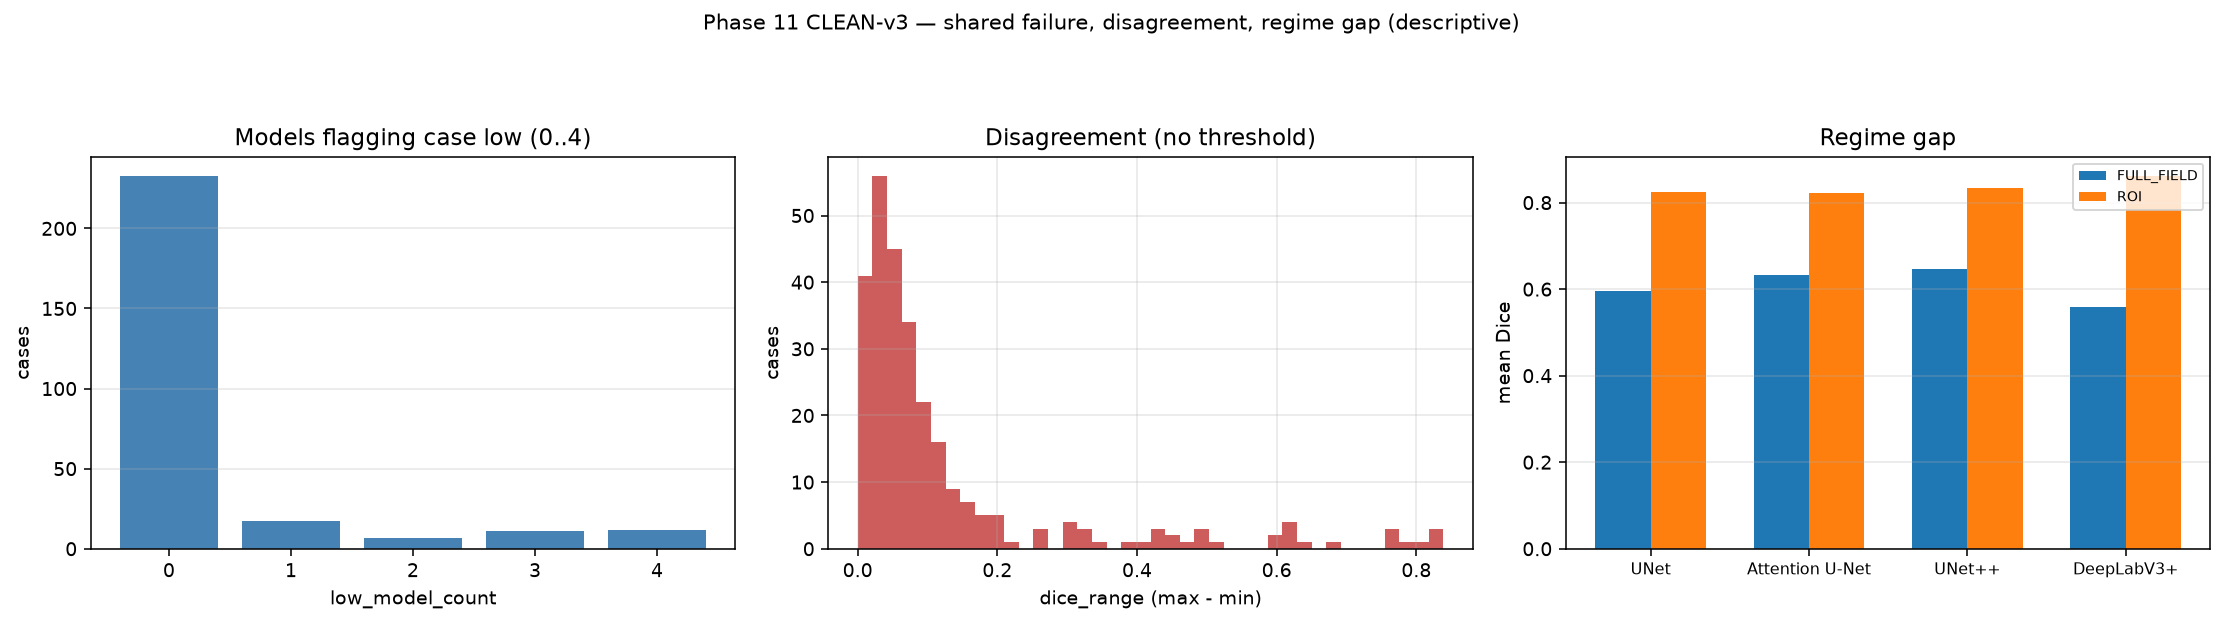

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle('Phase 11 CLEAN-v3 — shared failure, disagreement, regime gap (descriptive)', fontsize=11)
ax = axes[0]
ax.bar([str(i) for i in range(5)], [int((paired.low_model_count==i).sum()) for i in range(5)], color='steelblue')
ax.set_xlabel('low_model_count'); ax.set_ylabel('cases'); ax.set_title('Models flagging case low (0..4)')
ax.grid(True, alpha=.3, axis='y')
ax = axes[1]
ax.hist(disag.dice_range, bins=40, color='indianred')
ax.set_xlabel('dice_range (max - min)'); ax.set_ylabel('cases'); ax.set_title('Disagreement (no threshold)')
ax.grid(True, alpha=.3)
ax = axes[2]
w=0.35; x=np.arange(len(fa.MODELS))
ff = regime[regime.acquisition_type=='FULL_FIELD'].set_index('model_display')['mean_dice']
roi = regime[regime.acquisition_type=='ROI'].set_index('model_display')['mean_dice']
ax.bar(x-w/2, [ff[fa.DISPLAY[k]] for k in fa.MODELS], w, label='FULL_FIELD')
ax.bar(x+w/2, [roi[fa.DISPLAY[k]] for k in fa.MODELS], w, label='ROI')
ax.set_xticks(x); ax.set_xticklabels([fa.DISPLAY[k] for k in fa.MODELS], fontsize=8)
ax.set_ylabel('mean Dice'); ax.set_title('Regime gap'); ax.legend(fontsize=7); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(rect=[0,0,1,0.9])
p3 = fa.FIGURES/'phase11_clean_v3_shared_and_disagreement.png'; fig.savefig(p3, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p3)))


## 19. Category-Stratified Failures (metadata subgroups)


In [17]:
cat = pd.read_csv(fa.TABLES/'phase11_clean_v3_failure_by_category.csv')
display(cat[['model_display','category','n','mean_dice','empty_pred_pct','object_recall']])
print()
print('Bladder/Kidney/Ureteric are SUBGROUP METADATA of a binary segmentation target,')
print('not pixel classes. Ureteric n=24 - do not overinterpret.')


,model_display,category,n,mean_dice,empty_pred_pct,object_recall
0,Attention U-Net,Bladder_Stone,144,0.726648,0.020833,0.910180
1,Attention U-Net,Kidney_Stone,112,0.775580,0.000000,0.947368
2,Attention U-Net,Ureteric_Stone,24,0.800057,0.000000,0.892857
3,DeepLabV3+,Bladder_Stone,144,0.722072,0.048611,0.868263
4,DeepLabV3+,Kidney_Stone,112,0.783311,0.026786,0.909774
5,DeepLabV3+,Ureteric_Stone,24,0.772779,0.041667,0.821429
6,UNet,Bladder_Stone,144,0.714974,0.034722,0.880240
7,UNet,Kidney_Stone,112,0.770492,0.017857,0.924812
8,UNet,Ureteric_Stone,24,0.755015,0.041667,0.857143
9,UNet++,Bladder_Stone,144,0.748843,0.027778,0.916168



Bladder/Kidney/Ureteric are SUBGROUP METADATA of a binary segmentation target,
not pixel classes. Ureteric n=24 - do not overinterpret.


## 20. Historical-Style Deterministic Hard-Case Cohort (UNet++ anchor)


In [18]:
display(cohort[['selection_order','stratum','sample_id','acquisition','dice',
                'prediction_empty','missed_gt_eval_components','fp_eval_components']])
print()
print('target 16 | actual', len(cohort), '| strata:', cohort['stratum'].value_counts().to_dict())
print('acquisition mix:', cohort['acquisition'].value_counts().to_dict())
print()
print('Selection is deterministic and prediction-dependent by design (failure cohort).')
print('It must NOT be confused with the prediction-independent Phase-10 gallery.')


,selection_order,stratum,sample_id,acquisition,dice,prediction_empty,missed_gt_eval_components,fp_eval_components
0,1,A_EMPTY_PREDICTION,14d07b995aba3f2559d9a474c586495c,ROI,2.758925e-12,True,1,0
1,2,A_EMPTY_PREDICTION,5dd4436a2065b8855ce1dfbed228bce7,FULL_FIELD,1.234568e-09,True,2,0
2,3,A_EMPTY_PREDICTION,b0473630de9211114c94c7dc0363ebd9,FULL_FIELD,4.166667e-09,True,1,0
3,4,A_EMPTY_PREDICTION,416e6f7d9e35c6bf4bde51e191a7e92d,FULL_FIELD,6.666667e-09,True,2,0
4,5,B_MISSED_COMPONENT,70594587779736d8a7c391bd36df1e86,FULL_FIELD,6.329114e-10,False,2,1
5,6,B_MISSED_COMPONENT,abe658fa57a12b1665a96d00beeffae0,FULL_FIELD,1.250000e-09,False,2,1
6,7,B_MISSED_COMPONENT,8c8d2107815002b7913bd6a42f93b394,FULL_FIELD,9.090909e-09,True,2,0
7,8,B_MISSED_COMPONENT,501570377c27ca3a1b04f8e78ebbaa45,FULL_FIELD,3.012048e-10,False,1,1
8,9,C_HIGH_FP_DECILE,f374de139d4b8b68e45b68867d11b519,ROI,8.187392e-01,False,0,12
9,10,C_HIGH_FP_DECILE,f64a3a56bf7d22a21b0683166d3e8dec,ROI,8.682302e-01,False,0,11



target 16 | actual 16 | strata: {'A_EMPTY_PREDICTION': 4, 'B_MISSED_COMPONENT': 4, 'C_HIGH_FP_DECILE': 4, 'D_LOW_DICE_DECILE': 4}
acquisition mix: {'FULL_FIELD': 10, 'ROI': 6}

Selection is deterministic and prediction-dependent by design (failure cohort).
It must NOT be confused with the prediction-independent Phase-10 gallery.


## 21. Hard-Case Four-Model Visual Analysis


In [19]:
import numpy as np
sel = cohort['sample_id'].tolist()
preds = fa.predict_subset(sel, frame)
rows = cohort.set_index('sample_id')
paths = []
for sid in sel:
    rec = preds[sid]; gt = rec['gt']; src = rec['src']; meta = rec['meta']
    r = rows.loc[sid]
    stratum = fa.size_stratum_of_case(gt, meta['acquisition'])
    ncol = 2 + 3*len(fa.MODELS)
    fig, axes = plt.subplots(1, ncol, figsize=(2.6*ncol, 3.4))
    fig.suptitle(f"Hard case {int(r['selection_order'])} · {r['stratum']} · {sid[:12]} · "
                 f"{meta['category']} · {meta['acquisition']} · native {meta['native'][1]}x{meta['native'][0]} · "
                 f"size: {stratum}\nanchor=UNet++ (HISTORICAL_REPLICATION_ANALYSIS_ANCHOR)",
                 fontsize=10)
    axes[0].imshow(src, cmap='gray', vmin=0, vmax=255); axes[0].set_title('Source', fontsize=8); axes[0].axis('off')
    axes[1].imshow(gt, cmap='gray', vmin=0, vmax=1);   axes[1].set_title('Binary GT', fontsize=8); axes[1].axis('off')
    for i, k in enumerate(fa.MODELS):
        prob = rec['preds'][k]
        pred = (prob >= fa.THRESHOLD).astype(np.uint8)
        gtr = np.array(Image.fromarray(gt).resize((pred.shape[1], pred.shape[0]), Image.NEAREST))
        m = fa._case_metrics(gtr, prob)
        em = fa._error_map(gtr, pred)
        b = 2 + i*3
        axes[b].imshow(prob, cmap='viridis', vmin=0, vmax=1)
        axes[b].set_title(f"{fa.DISPLAY[k]}\nprob", fontsize=8); axes[b].axis('off')
        axes[b+1].imshow(pred, cmap='gray', vmin=0, vmax=1)
        axes[b+1].set_title('pred t=0.5', fontsize=8); axes[b+1].axis('off')
        axes[b+2].imshow(em)
        axes[b+2].set_title(f"err map\nDice={m['dice']:.3f} empty={m['prediction_empty']}", fontsize=8)
        axes[b+2].axis('off')
    plt.tight_layout(rect=[0, 0.02, 1, 0.86])
    fp_ = fa.FIGURES/f"phase11_clean_v3_hardcase_{int(r['selection_order']):02d}.png"
    fig.savefig(fp_, dpi=110, bbox_inches='tight'); plt.close(fig); paths.append(fp_)
print('generated', len(paths), 'hard-case panels')


generated 16 hard-case panels


phase11_clean_v3_hardcase_01.png


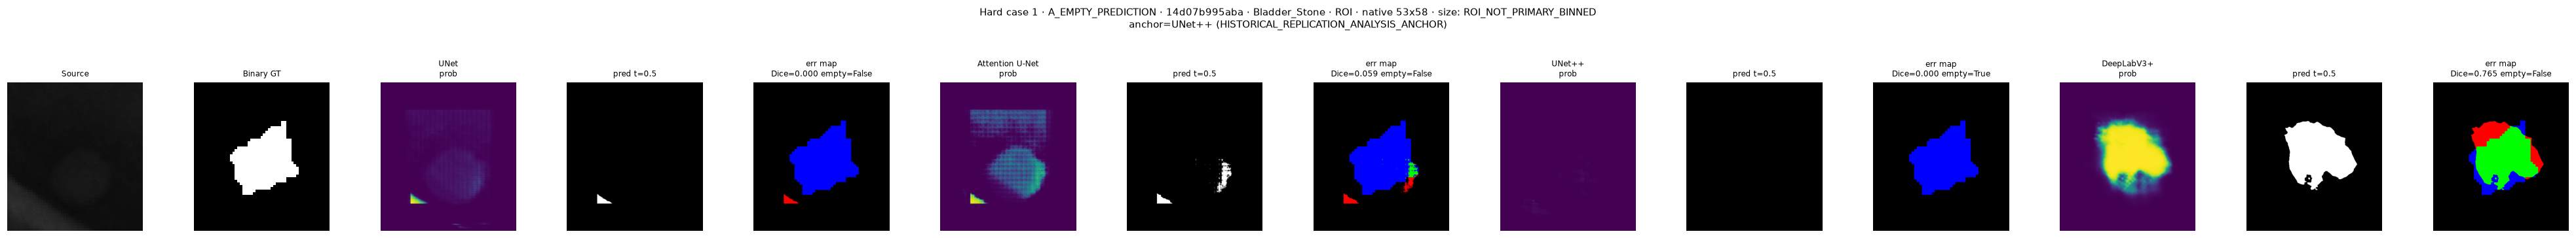

phase11_clean_v3_hardcase_02.png


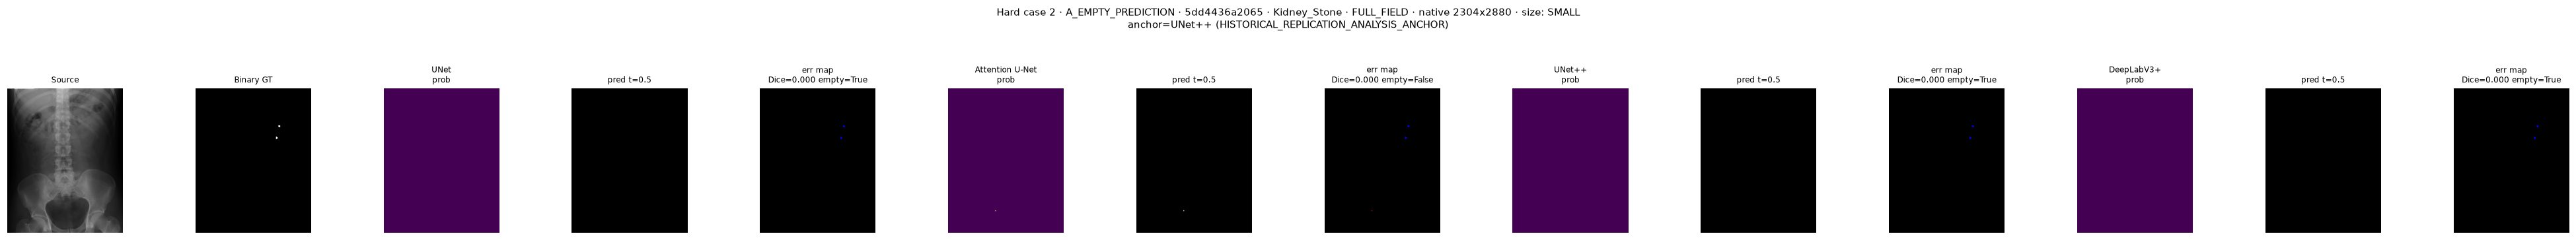

phase11_clean_v3_hardcase_03.png


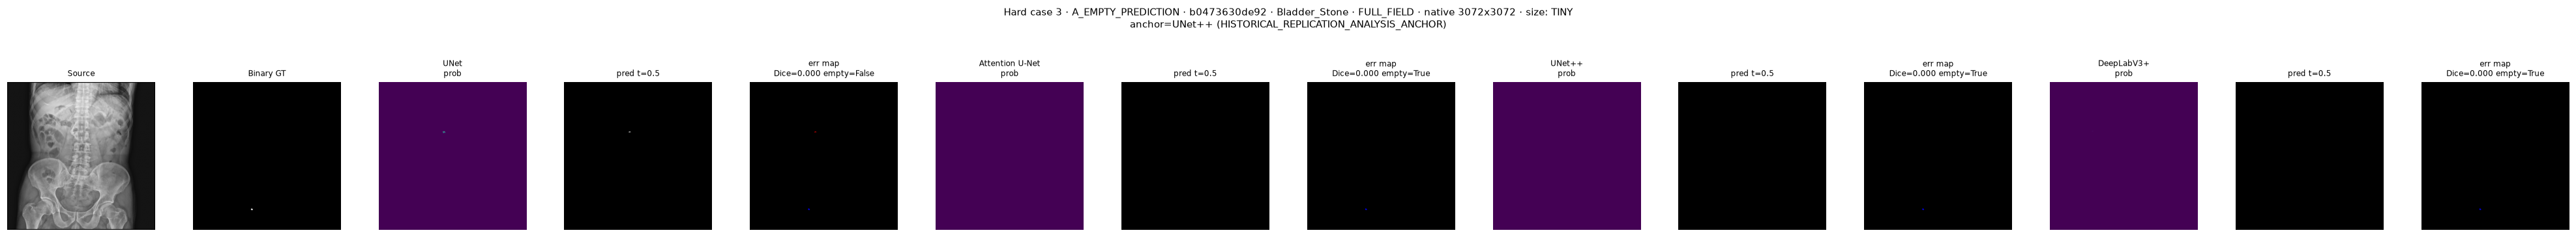

phase11_clean_v3_hardcase_04.png


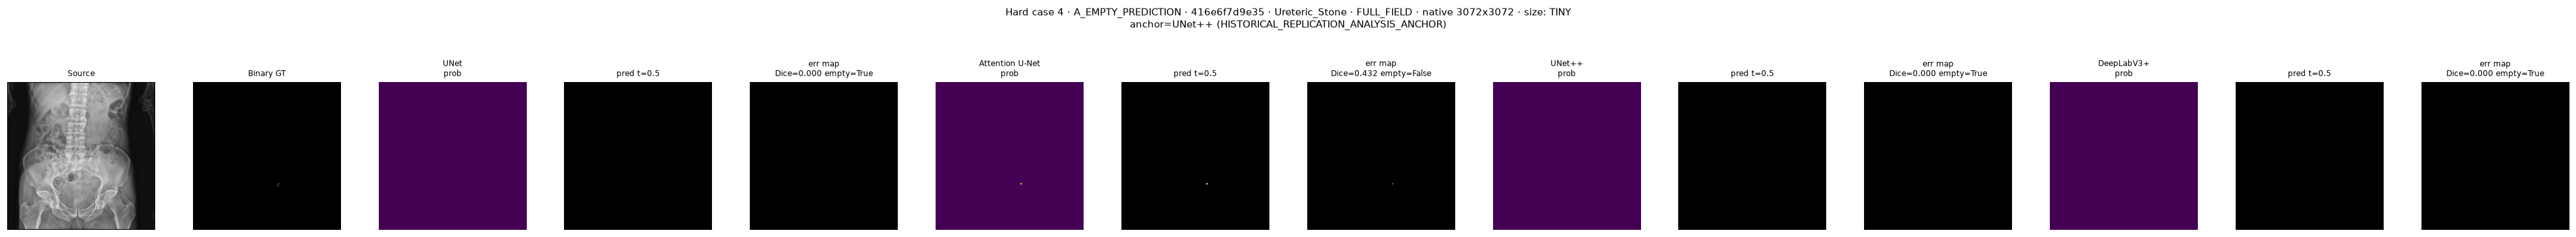

phase11_clean_v3_hardcase_05.png


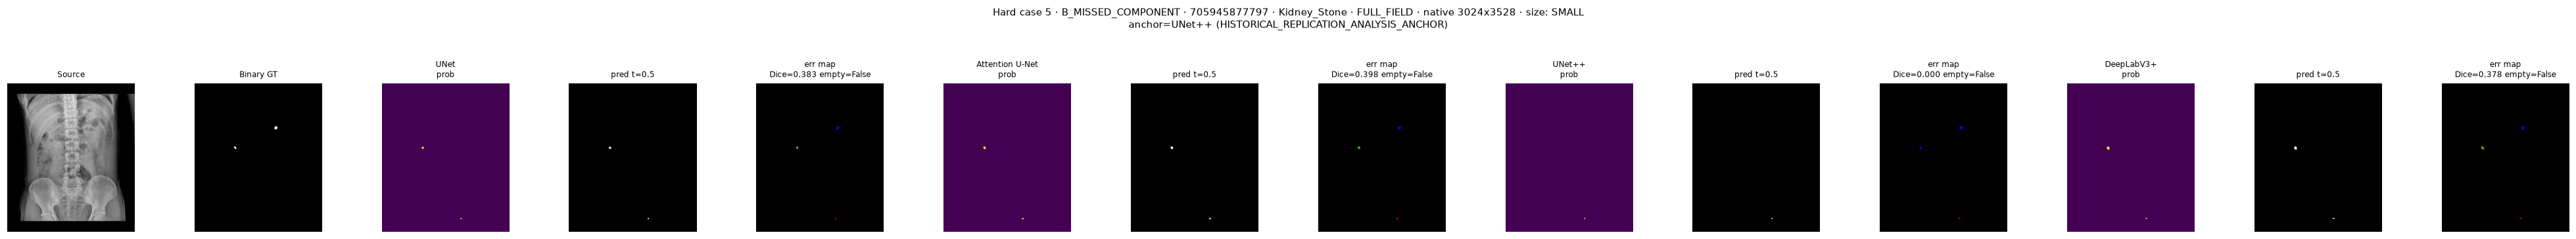

phase11_clean_v3_hardcase_06.png


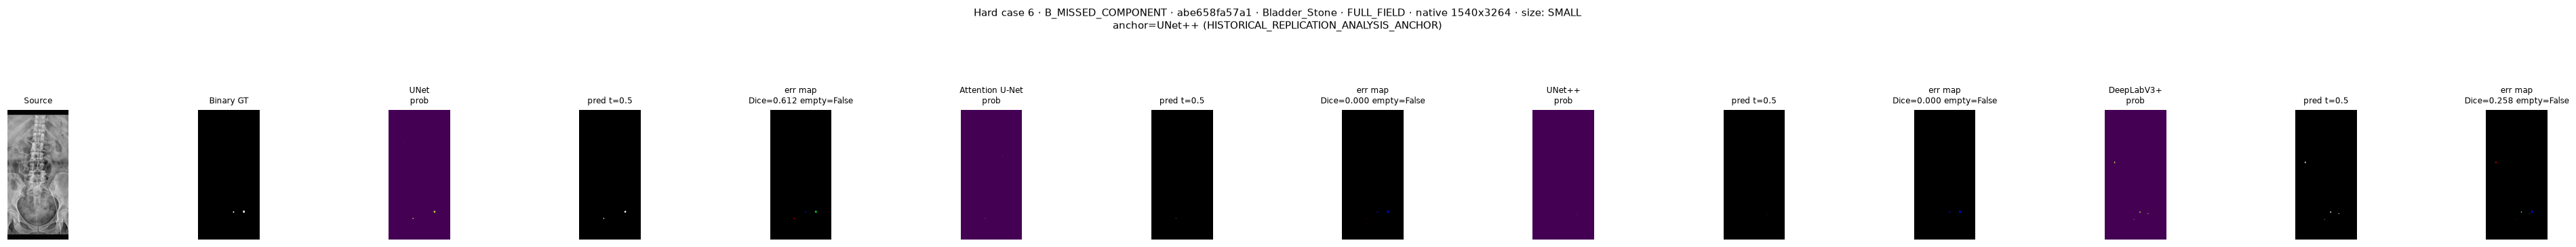

phase11_clean_v3_hardcase_07.png


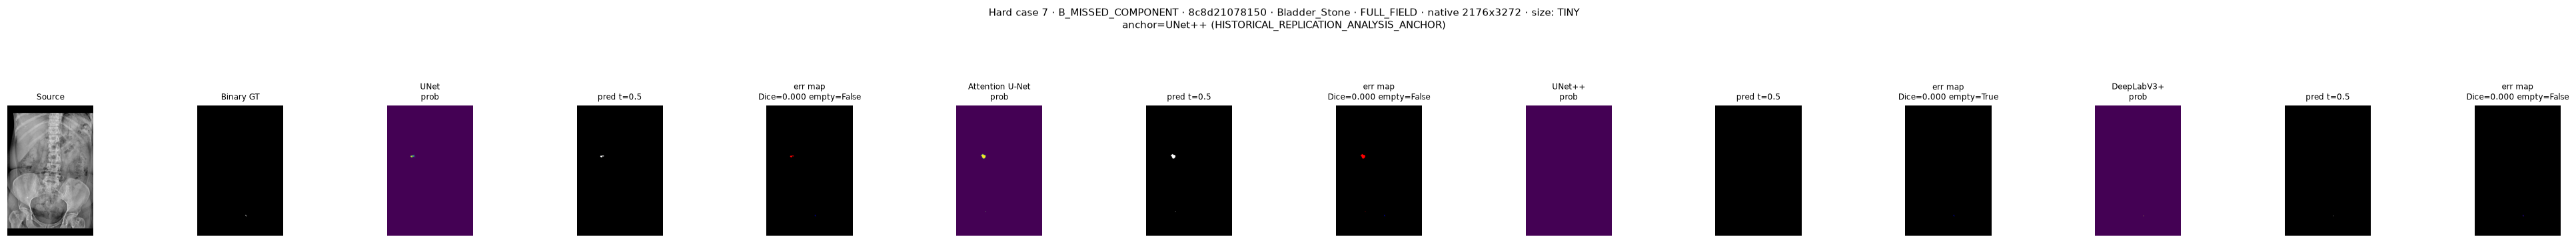

phase11_clean_v3_hardcase_08.png


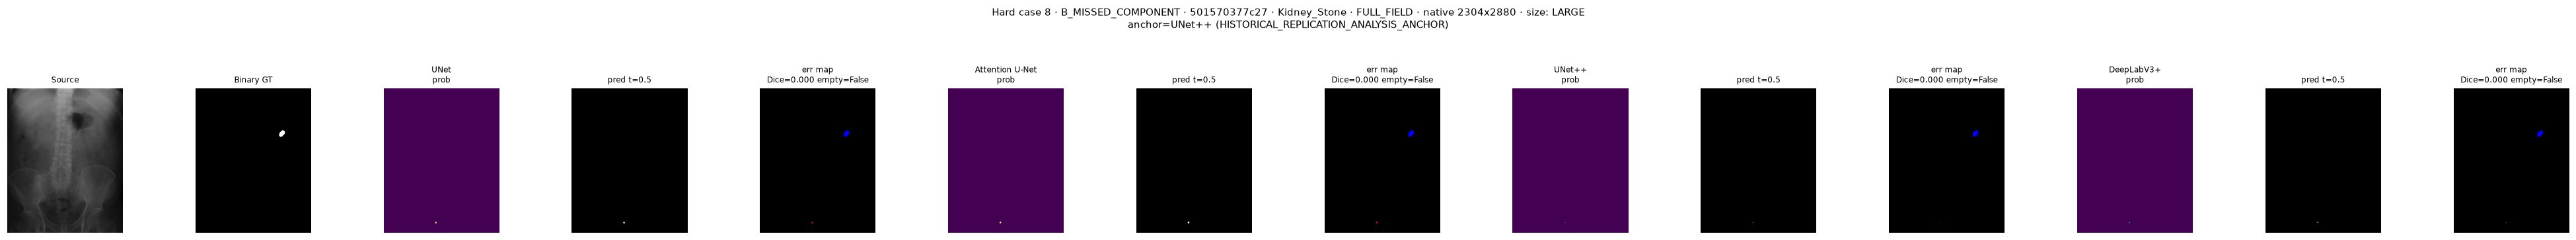

phase11_clean_v3_hardcase_09.png


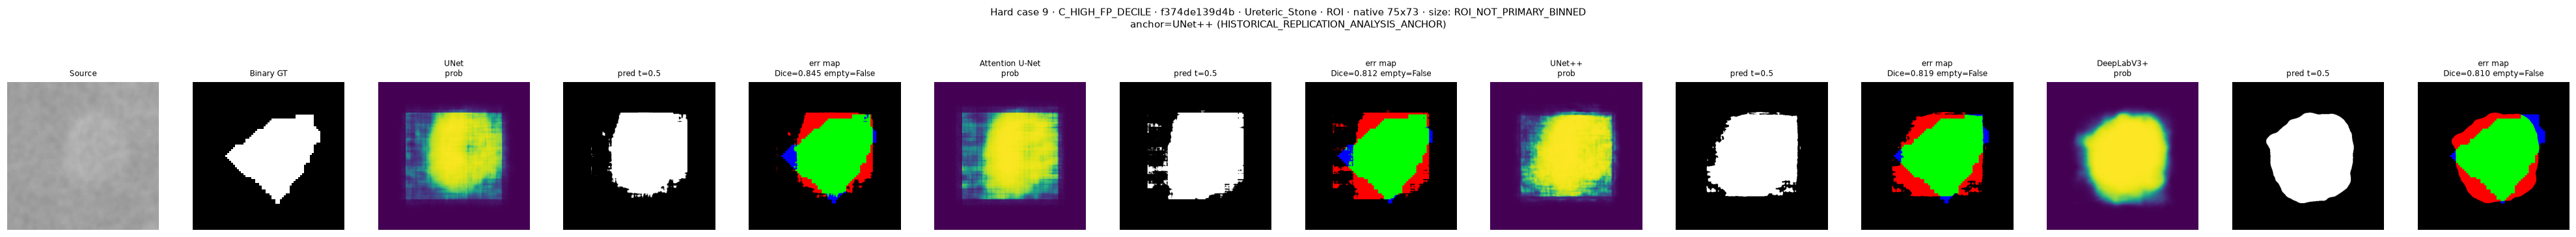

phase11_clean_v3_hardcase_10.png


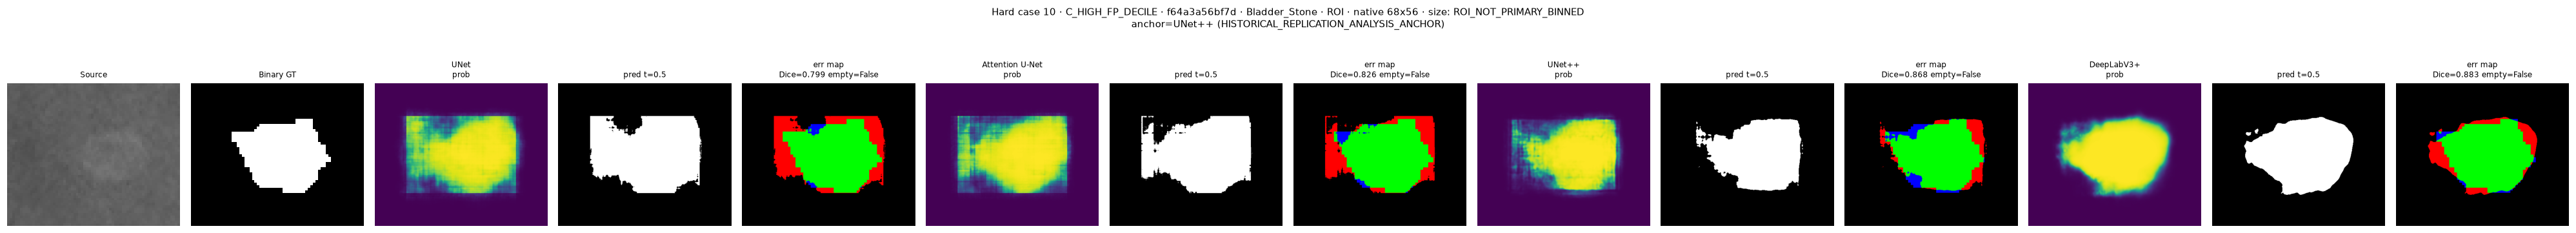

phase11_clean_v3_hardcase_11.png


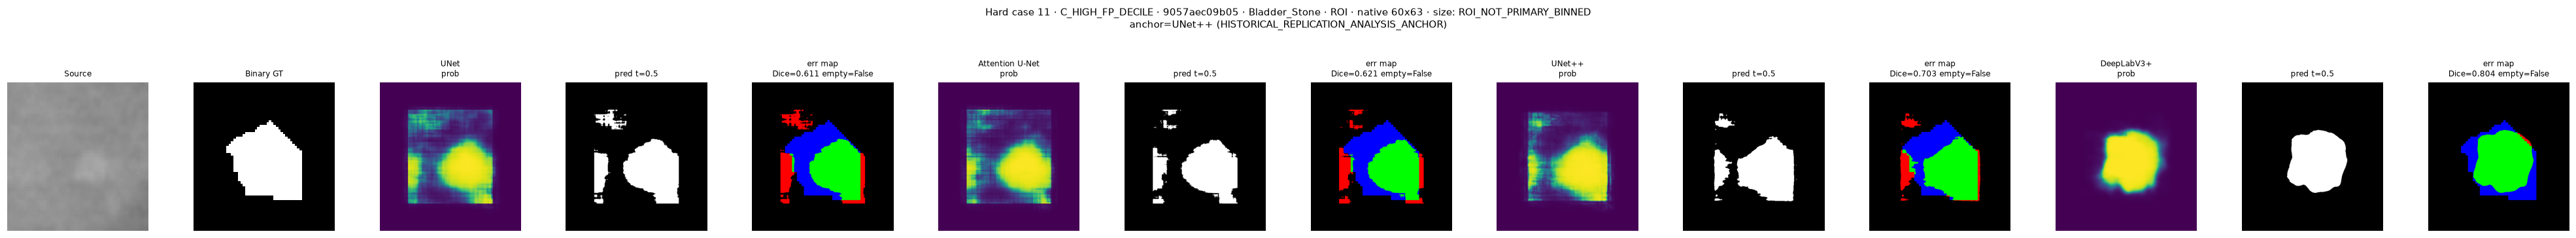

phase11_clean_v3_hardcase_12.png


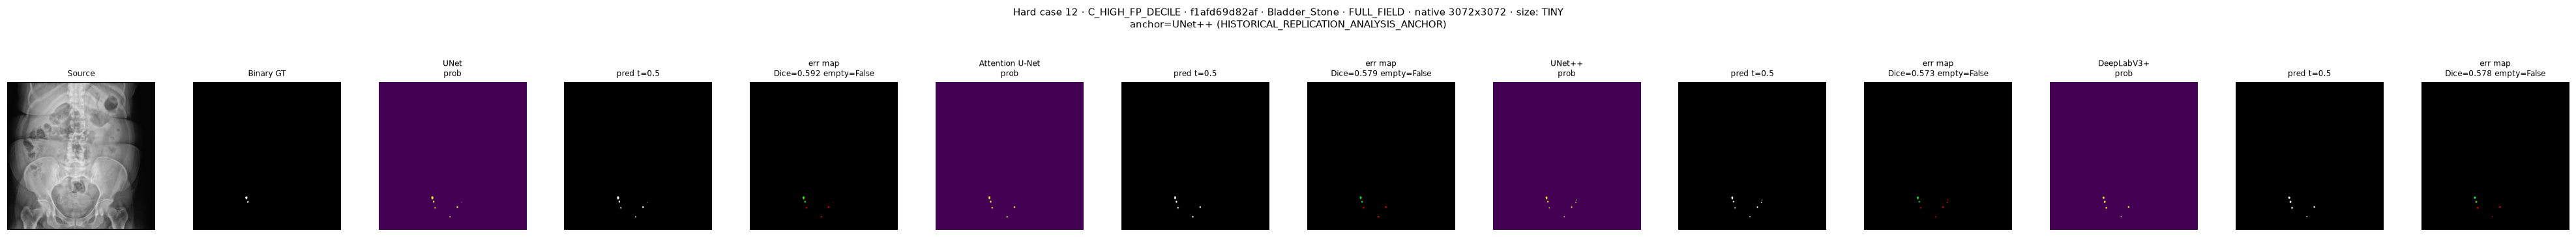

phase11_clean_v3_hardcase_13.png


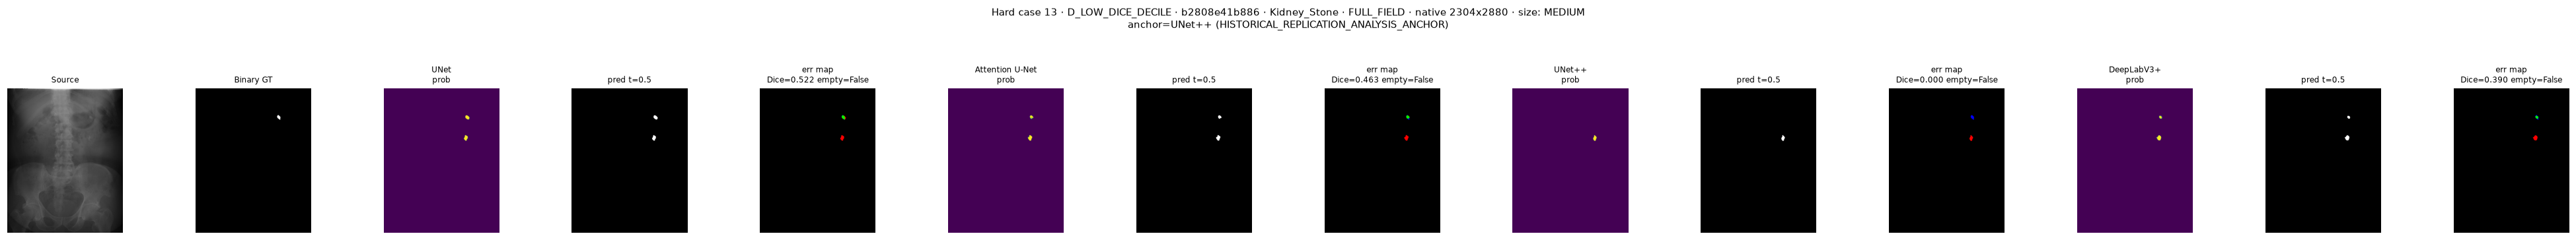

phase11_clean_v3_hardcase_14.png


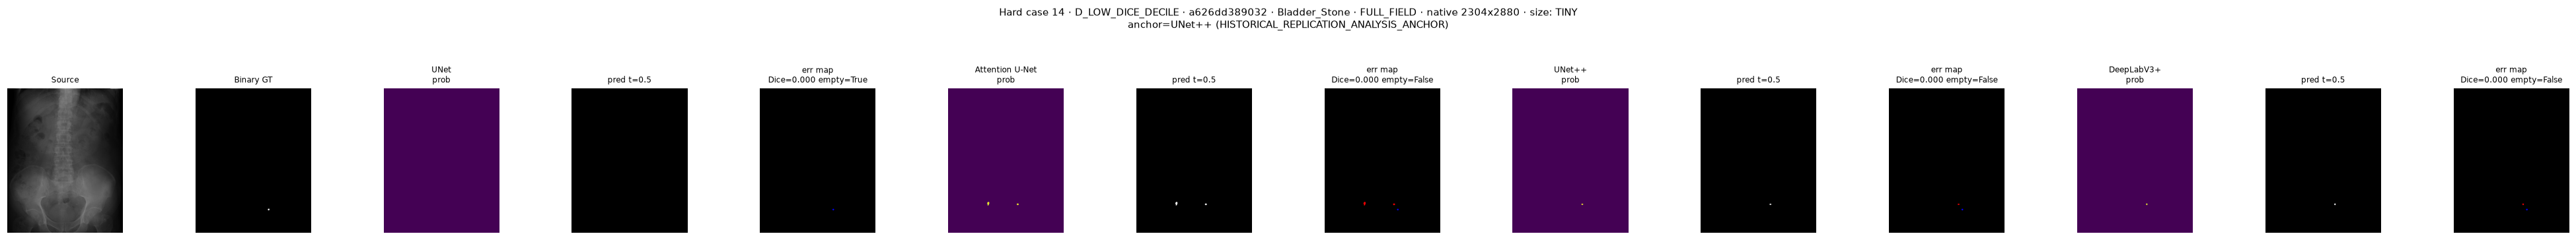

phase11_clean_v3_hardcase_15.png


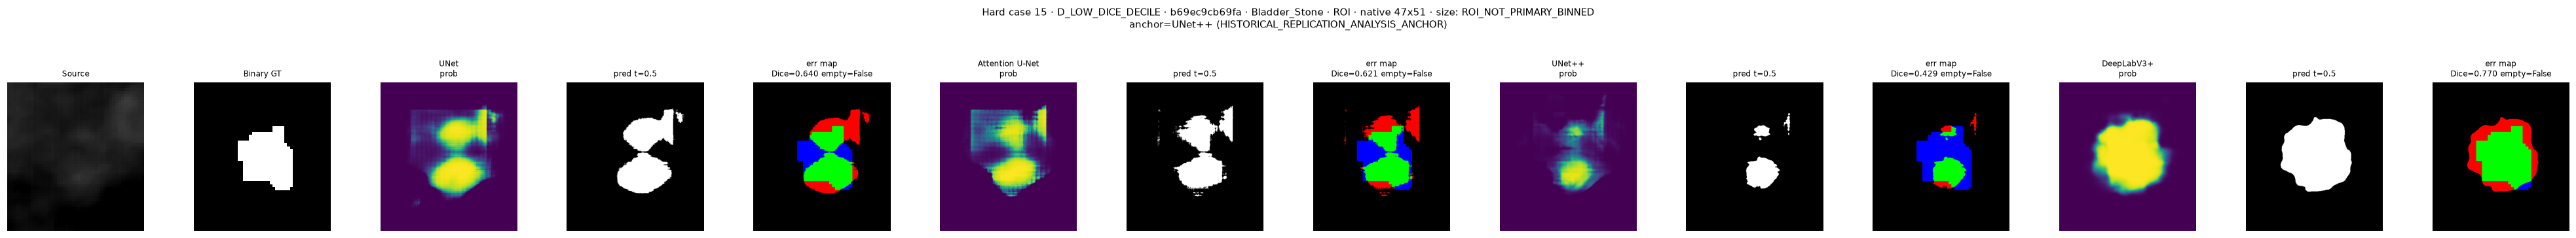

phase11_clean_v3_hardcase_16.png


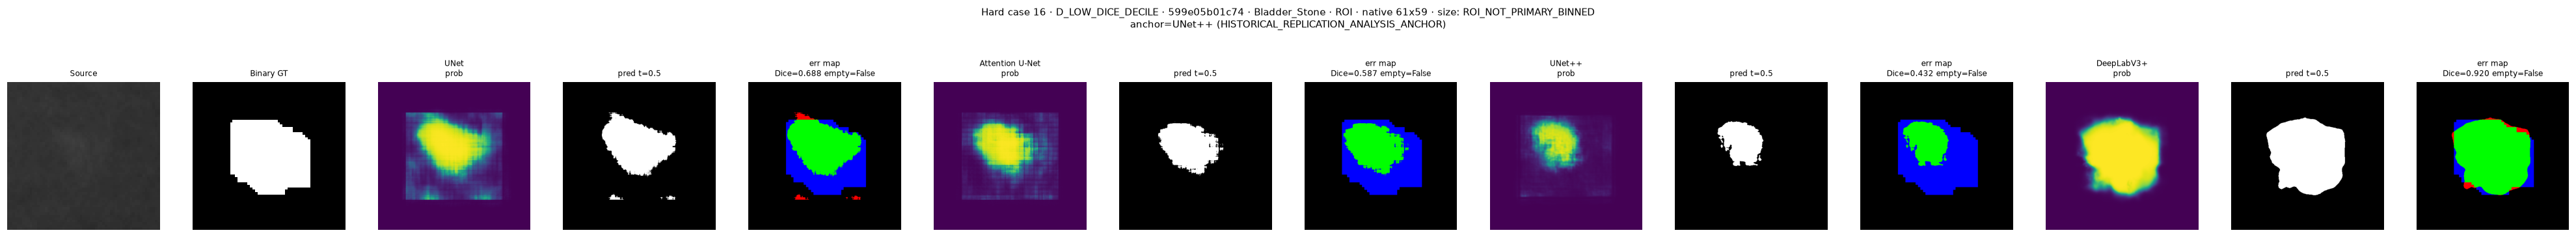

In [20]:
for fp_ in paths:
    print(fp_.name)
    display(IPImage(filename=str(fp_)))


## 22. Top-Disagreement Visual Analysis (diagnostic only)

Four highest `dice_range` cases, sorted `dice_range desc, sample_id asc`.
`ARCHITECTURE_DISAGREEMENT_DESCRIPTIVE_ONLY`.


In [21]:
display(top4[['sample_id','dice_range','dice_min','dice_max']]
        .assign(status='DESCRIPTIVE_DISAGREEMENT_DIAGNOSTIC_ONLY'))
print()
print('These are NOT merged into the historical hard cohort unless independently selected.')
seld = top4['sample_id'].tolist()
overlap = [s for s in seld if s in set(cohort['sample_id'])]
print('overlap with hard cohort:', overlap if overlap else 'NONE')
preds_d = fa.predict_subset(seld, frame)
dp = []
for sid in seld:
    rec = preds_d[sid]; gt = rec['gt']; src = rec['src']; meta = rec['meta']
    rr = disag[disag.sample_id==sid].iloc[0]
    ncol = 2 + 3*len(fa.MODELS)
    fig, axes = plt.subplots(1, ncol, figsize=(2.6*ncol, 3.4))
    fig.suptitle(f"Disagreement · {sid[:12]} · {meta['category']} · {meta['acquisition']} · "
                 f"dice_range={rr['dice_range']:.3f} (min {rr['dice_min']:.3f} / max {rr['dice_max']:.3f})\n"
                 f"ARCHITECTURE_DISAGREEMENT_DESCRIPTIVE_ONLY", fontsize=10)
    axes[0].imshow(src, cmap='gray', vmin=0, vmax=255); axes[0].set_title('Source', fontsize=8); axes[0].axis('off')
    axes[1].imshow(gt, cmap='gray', vmin=0, vmax=1); axes[1].set_title('Binary GT', fontsize=8); axes[1].axis('off')
    for i, k in enumerate(fa.MODELS):
        prob = rec['preds'][k]; pred = (prob >= fa.THRESHOLD).astype(np.uint8)
        gtr = np.array(Image.fromarray(gt).resize((pred.shape[1], pred.shape[0]), Image.NEAREST))
        m = fa._case_metrics(gtr, prob); b = 2 + i*3
        axes[b].imshow(prob, cmap='viridis', vmin=0, vmax=1)
        axes[b].set_title(f"{fa.DISPLAY[k]}\nprob", fontsize=8); axes[b].axis('off')
        axes[b+1].imshow(pred, cmap='gray', vmin=0, vmax=1)
        axes[b+1].set_title('pred', fontsize=8); axes[b+1].axis('off')
        axes[b+2].imshow(fa._error_map(gtr, pred))
        axes[b+2].set_title(f"err map\nDice={m['dice']:.3f}", fontsize=8); axes[b+2].axis('off')
    plt.tight_layout(rect=[0, 0.02, 1, 0.86])
    fq = fa.FIGURES/f"phase11_clean_v3_disagreement_{sid[:8]}.png"
    fig.savefig(fq, dpi=110, bbox_inches='tight'); plt.close(fig); dp.append(fq)
print('generated', len(dp), 'disagreement panels')


,sample_id,dice_range,dice_min,dice_max,status
0,1ba084b5439ffee651b4f5e0697e2209,0.838710,5.555556e-09,0.838710,DESCRIPTIVE_DISAGREEMENT_DIAGNOSTIC_ONLY
1,f860cbfe7c79e5772795a64bac5de7e7,0.833333,3.125000e-09,0.833333,DESCRIPTIVE_DISAGREEMENT_DIAGNOSTIC_ONLY
2,717a1ec0a082fae24e2341341ca83e77,0.831169,2.439024e-09,0.831169,DESCRIPTIVE_DISAGREEMENT_DIAGNOSTIC_ONLY
3,66b947d8ead11ae1260bc3142ca1707d,0.800000,7.142857e-09,0.800000,DESCRIPTIVE_DISAGREEMENT_DIAGNOSTIC_ONLY



These are NOT merged into the historical hard cohort unless independently selected.
overlap with hard cohort: NONE


generated 4 disagreement panels


phase11_clean_v3_disagreement_1ba084b5.png


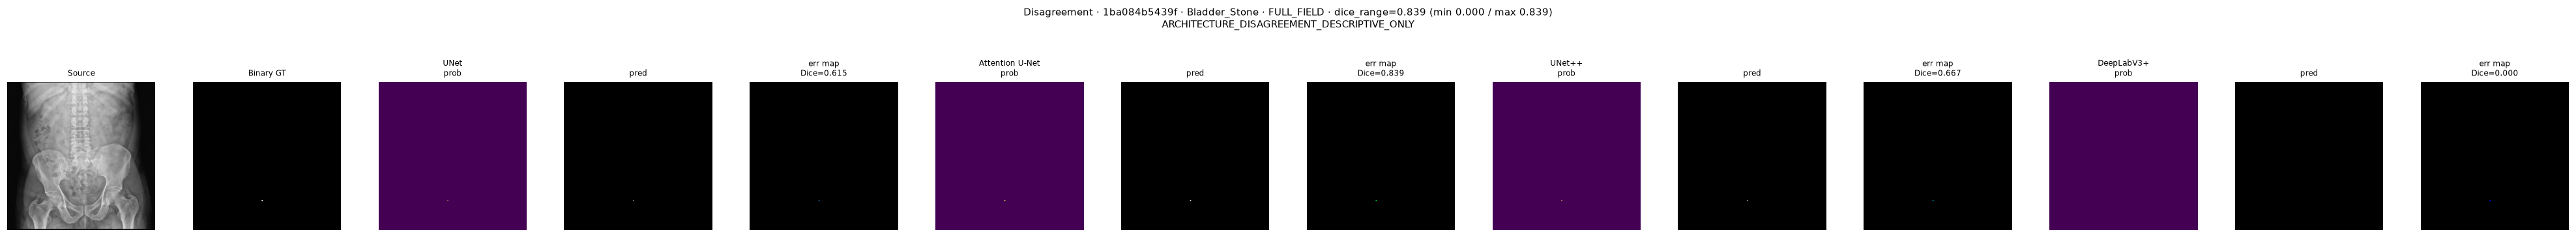

phase11_clean_v3_disagreement_f860cbfe.png


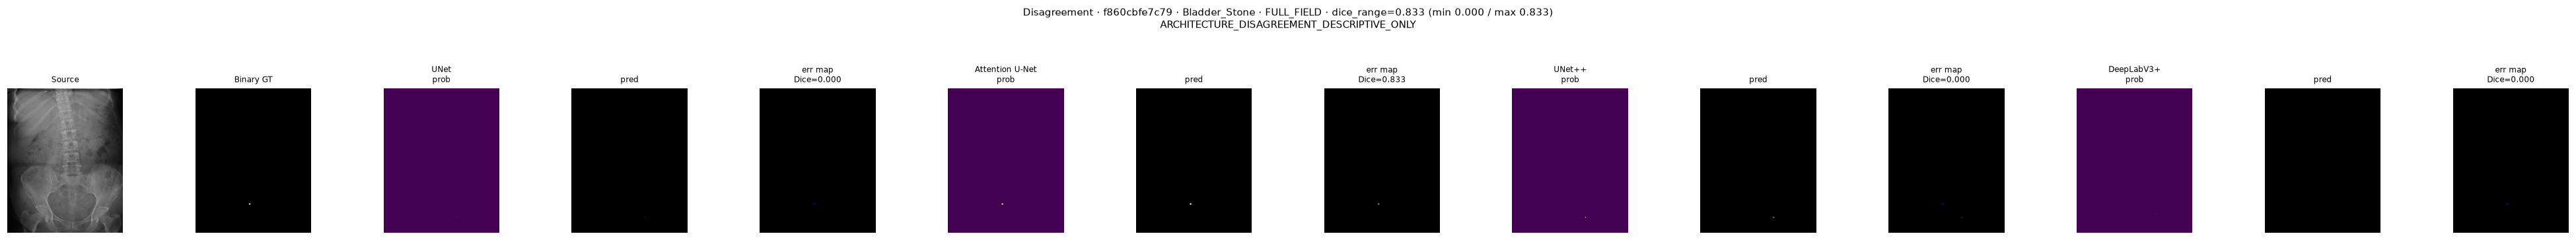

phase11_clean_v3_disagreement_717a1ec0.png


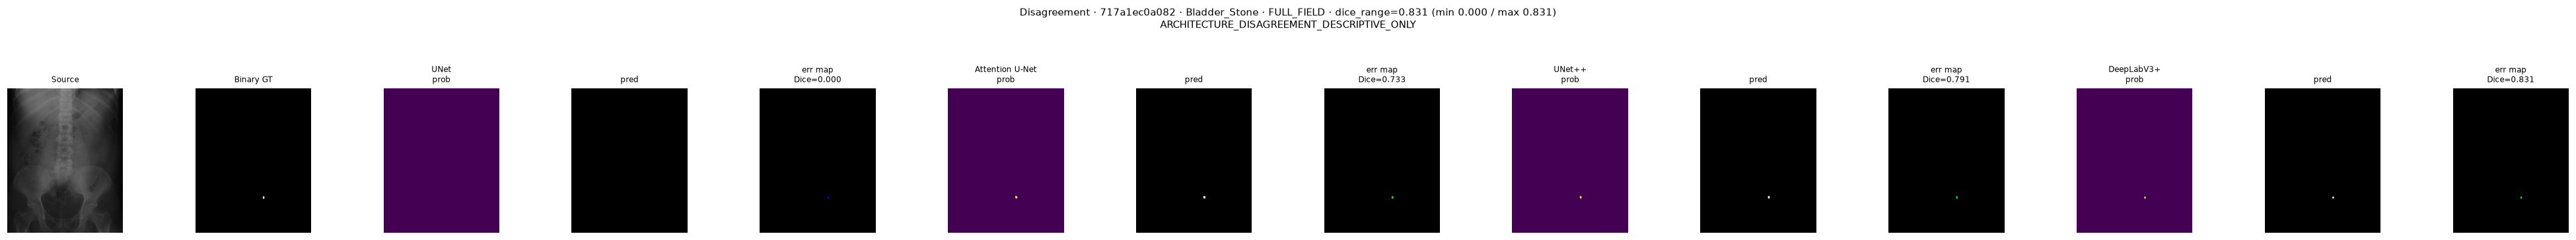

phase11_clean_v3_disagreement_66b947d8.png


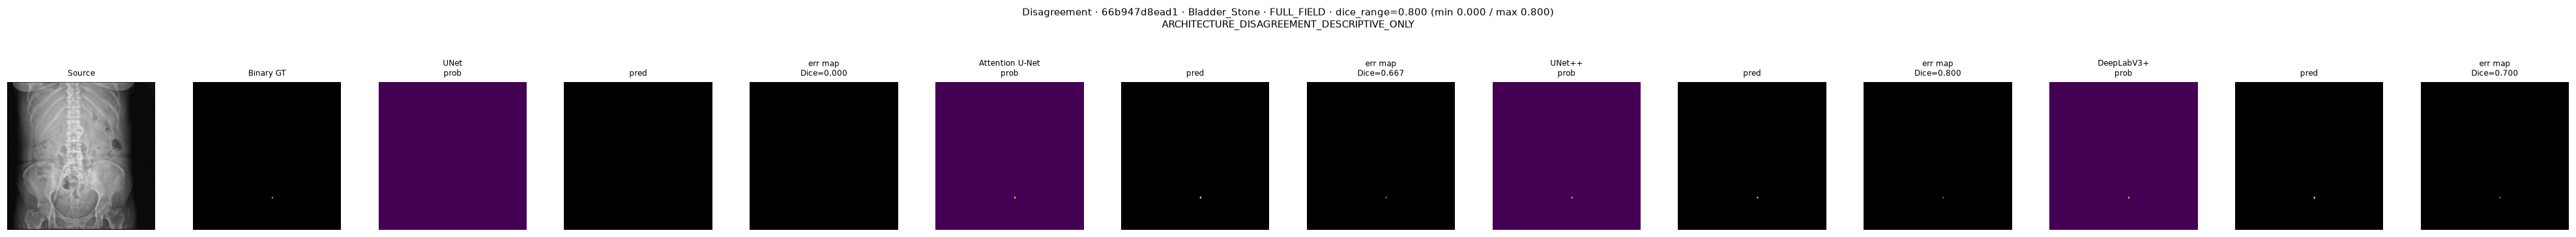

In [22]:
for fq in dp:
    print(fq.name)
    display(IPImage(filename=str(fq)))


## 23. Phase-11 → Phase-12 Bridge Evidence

`OBSERVED_DIAGNOSTIC_EVIDENCE`. We state whether the clean-v3 pattern motivates the
historical Oracle-ROI rationale — **without** selecting a Phase-12 model and **without**
claiming ROI solves the problem.


In [23]:
bridge = pd.read_csv(fa.TABLES/'phase11_clean_v3_phase12_bridge_evidence.csv')
display(bridge[['evidence','value','verdict','status']])
print()
print('No Phase-12 reference model is selected here: SUPERVISOR_DECISION_REQUIRED.')


,evidence,value,verdict,status
0,FULL_FIELD vs ROI mean-Dice gap,0.2276,MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
1,FULL_FIELD mean Dice (per model),"{'Attention U-Net': 0.6317, 'DeepLabV3+': 0.5591, 'UNet': 0.5965, 'UNet++': 0.6455}",MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
2,FULL_FIELD TINY components with incomplete/missed detection,"72 native TINY components; components in partially/missed cases per model: {'UNet': 29, 'Attention U-Net': 22, 'UNet++': 20, 'DeepLabV3+': 33}",MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
3,FULL_FIELD SMALL components with incomplete/missed detection,"28 native SMALL components; components in partially/missed cases per model: {'UNet': 10, 'Attention U-Net': 8, 'UNet++': 7, 'DeepLabV3+': 10}",MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
4,multi-component partial/miss cases (per model),"{'UNet': 19, 'Attention U-Net': 16, 'UNet++': 16, 'DeepLabV3+': 22}",MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
5,empty predictions (FULL_FIELD vs ROI),FULL_FIELD 3-11 per model; ROI 0-1 per model,MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
6,HD95 valid median (per model),"{'Attention U-Net': 43.67, 'DeepLabV3+': 33.23, 'UNet': 44.93, 'UNet++': 36.51}",MIXED,OBSERVED_DIAGNOSTIC_EVIDENCE
7,FP component burden (mean per case),"{'Attention U-Net': 10.068, 'DeepLabV3+': 0.236, 'UNet': 10.157, 'UNet++': 1.654}",MIXED,OBSERVED_DIAGNOSTIC_EVIDENCE
8,ALL_FOUR_LOW shared-failure cases,12/280,MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE
9,cases where >=3 models lose components,23,MOTIVATES_ORACLE_ROI_TEST,OBSERVED_DIAGNOSTIC_EVIDENCE



No Phase-12 reference model is selected here: SUPERVISOR_DECISION_REQUIRED.


## 24. Limitations

- Single seed (42); no Phase-29 reproducibility, no Phase-31 significance testing.
- VAL only (280 KUB cases); TEST locked to Phase 39 — no generalization claim.
- Ureteric_Stone n=24 — unstable subgroup.
- Component-space attribution across native (size) vs evaluation-512 (detection) is
  approximate; resize can merge components, so per-component cross-space claims are
  reported at case level where attribution is uncertain.
- HD95 invalid cases (empty prediction / empty GT) counted but excluded from HD95 statistics.


## 25. Historical-v2 Separation

| Quantity | HISTORICAL_v2 (provenance only) | CLEAN_v3 (used) |
|---|---|---|
| Dice Q10 | 0.5461063385009766 | per-model recomputed (see §7) |
| HD95 Q90 | 83.07246563841615 | 85.24095485204775 (UNet++ valid-only) |
| FP cutoff | 4 | 5.0 (UNet++ clean Q90) |
| Size taxonomy | `kub_size_v1` | `kub_size_clean_v3_v1` |
| VAL cases | 283 | 280 |

v2 values were **not** used as clean-v3 thresholds.


## 26. Complete Epoch Table — UNet

Upstream frozen training provenance, read-only from the Phase-10 normalized epoch table.
**Every epoch row displayed.**


In [24]:
t = pd.read_csv(fa.PHASE10_EPOCH_TABLES['unet'])
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM UNet ===')
print('  rows:', len(t), '| expected:', fa.EXPECTED_EPOCH_ROWS['unet'])
print('  first/last:', min(eps), '/', max(eps))
print('  missing   :', sorted(set(exp)-set(eps)))
print('  duplicates:', sorted({e for e in eps if eps.count(e)>1}))
print('  contiguous:', eps==exp)
assert len(t)==fa.EXPECTED_EPOCH_ROWS['unet'] and eps==exp
print()
display(t)


=== UPSTREAM UNet ===
  rows: 59 | expected: 59
  first/last: 1 / 59
  missing   : []
  duplicates: []
  contiguous: True



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,1,0.442458,0.465926,0.431176,0.340278,NaN,NaN,0.000100,NaN,1,0,268.742252,BEST_SAVED,NaN,NaN,True,False,0
1,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,2,0.392092,0.396965,0.456776,0.366742,NaN,NaN,0.000100,NaN,1,0,60.102438,BEST_SAVED,0.025599,NaN,True,False,0
2,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,3,0.367363,0.359159,0.490891,0.401569,NaN,NaN,0.000100,NaN,1,0,60.311679,BEST_SAVED,0.034116,NaN,True,False,0
3,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,4,0.351135,0.425429,0.497879,0.397826,NaN,NaN,0.000100,NaN,1,0,60.858533,BEST_SAVED,0.006987,NaN,True,False,0
4,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,5,0.335718,0.332848,0.530259,0.438920,NaN,NaN,0.000099,NaN,1,0,63.602900,BEST_SAVED,0.032380,NaN,True,False,0
5,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,6,0.321234,0.321200,0.545095,0.452030,NaN,NaN,0.000099,NaN,1,0,63.525723,BEST_SAVED,0.014836,NaN,True,False,0
6,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,7,0.306985,0.305672,0.579637,0.472824,NaN,NaN,0.000099,NaN,1,0,64.249523,BEST_SAVED,0.034542,NaN,True,False,0
7,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,8,0.292267,0.391134,0.563304,0.445191,NaN,NaN,0.000098,NaN,0,1,63.671509,LATEST_ONLY,-0.016333,NaN,False,False,1
8,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,9,0.272067,0.287922,0.638627,0.520392,NaN,NaN,0.000098,NaN,1,0,63.566675,BEST_SAVED,0.075323,NaN,True,False,0
9,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,10,0.261210,0.260292,0.654405,0.541183,NaN,NaN,0.000098,NaN,1,0,63.609702,BEST_SAVED,0.015778,NaN,True,False,0


## 27. Complete Epoch Table — Attention U-Net

Upstream frozen training provenance, read-only from the Phase-10 normalized epoch table.
**Every epoch row displayed.**


In [25]:
t = pd.read_csv(fa.PHASE10_EPOCH_TABLES['attention_unet'])
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM Attention U-Net ===')
print('  rows:', len(t), '| expected:', fa.EXPECTED_EPOCH_ROWS['attention_unet'])
print('  first/last:', min(eps), '/', max(eps))
print('  missing   :', sorted(set(exp)-set(eps)))
print('  duplicates:', sorted({e for e in eps if eps.count(e)>1}))
print('  contiguous:', eps==exp)
assert len(t)==fa.EXPECTED_EPOCH_ROWS['attention_unet'] and eps==exp
print()
display(t)


=== UPSTREAM Attention U-Net ===
  rows: 69 | expected: 69
  first/last: 1 / 69
  missing   : []
  duplicates: []
  contiguous: True



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,1,0.511852,0.492498,0.455501,0.364793,0.557557,0.601329,0.000100,0.455501,1,0,180.8,BEST_SAVED,NaN,NaN,True,False,0
1,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,2,0.421238,0.414937,0.453676,0.365484,0.583015,0.572629,0.000100,0.455501,0,1,73.8,LATEST_ONLY,-0.001825,0.000000,False,False,1
2,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,3,0.385591,0.402041,0.469479,0.383368,0.685439,0.592345,0.000100,0.469479,1,0,70.7,BEST_SAVED,0.015802,0.013977,True,False,0
3,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,4,0.363607,0.365701,0.492169,0.400162,0.595332,0.512817,0.000100,0.492169,1,0,70.3,BEST_SAVED,0.022690,0.022690,True,False,0
4,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,5,0.347567,0.357465,0.507544,0.418799,0.459013,0.673806,0.000099,0.507544,1,0,73.2,BEST_SAVED,0.015375,0.015375,True,False,0
5,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,6,0.335710,0.337032,0.542214,0.445455,0.538902,0.645993,0.000099,0.542214,1,0,73.1,BEST_SAVED,0.034670,0.034670,True,False,0
6,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,7,0.326942,0.326772,0.546270,0.452797,0.531451,0.653997,0.000099,0.546270,1,0,73.4,BEST_SAVED,0.004056,0.004056,True,False,0
7,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,8,0.313945,0.307033,0.566118,0.473826,0.656369,0.611473,0.000098,0.566118,1,0,74.5,BEST_SAVED,0.019848,0.019848,True,False,0
8,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,9,0.299837,0.293197,0.603426,0.499475,0.653554,0.661779,0.000098,0.603426,1,0,74.2,BEST_SAVED,0.037307,0.037307,True,False,0
9,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,10,0.285437,0.288194,0.604399,0.499341,0.690762,0.631612,0.000098,0.604399,1,0,74.3,BEST_SAVED,0.000973,0.000973,True,False,0


## 28. Complete Epoch Table — UNet++

Upstream frozen training provenance, read-only from the Phase-10 normalized epoch table.
**Every epoch row displayed.**


In [26]:
t = pd.read_csv(fa.PHASE10_EPOCH_TABLES['unetpp'])
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM UNet++ ===')
print('  rows:', len(t), '| expected:', fa.EXPECTED_EPOCH_ROWS['unetpp'])
print('  first/last:', min(eps), '/', max(eps))
print('  missing   :', sorted(set(exp)-set(eps)))
print('  duplicates:', sorted({e for e in eps if eps.count(e)>1}))
print('  contiguous:', eps==exp)
assert len(t)==fa.EXPECTED_EPOCH_ROWS['unetpp'] and eps==exp
print()
display(t)


=== UPSTREAM UNet++ ===
  rows: 85 | expected: 85
  first/last: 1 / 85
  missing   : []
  duplicates: []
  contiguous: True



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,1,0.438780,0.416830,0.454545,0.363090,0.678880,0.502299,0.000100,0.454545,1,0,290.9,BEST_SAVED,NaN,NaN,True,False,0
1,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,2,0.388098,0.421986,0.468632,0.378370,0.704706,0.592291,0.000100,0.468632,1,0,180.4,BEST_SAVED,0.014087,0.014087,True,False,0
2,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,3,0.363468,0.443350,0.465154,0.372904,0.571621,0.639822,0.000100,0.468632,0,1,180.6,LATEST_ONLY,-0.003477,0.000000,False,False,1
3,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,4,0.352005,0.348390,0.519276,0.427362,0.499869,0.639654,0.000100,0.519276,1,0,180.6,BEST_SAVED,0.054121,0.050644,True,False,0
4,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,5,0.336932,0.323569,0.554764,0.460919,0.562959,0.635015,0.000099,0.554764,1,0,178.6,BEST_SAVED,0.035489,0.035489,True,False,0
5,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,6,0.325398,0.328325,0.562319,0.462126,0.589963,0.666141,0.000099,0.562319,1,0,178.7,BEST_SAVED,0.007554,0.007554,True,False,0
6,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,7,0.310921,0.328777,0.551526,0.443353,0.545447,0.666942,0.000099,0.562319,0,1,178.6,LATEST_ONLY,-0.010793,0.000000,False,False,1
7,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,8,0.297655,0.320062,0.547991,0.450617,0.499140,0.808599,0.000098,0.562319,0,2,178.9,LATEST_ONLY,-0.003535,0.000000,False,False,2
8,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,9,0.265427,0.276223,0.620099,0.504560,0.570966,0.801323,0.000098,0.620099,1,0,178.9,BEST_SAVED,0.072109,0.057781,True,False,0
9,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,10,0.258951,0.272386,0.659271,0.536225,0.616674,0.808719,0.000098,0.659271,1,0,179.0,BEST_SAVED,0.039172,0.039172,True,False,0


## 29. Complete Epoch Table — DeepLabV3+

Upstream frozen training provenance, read-only from the Phase-10 normalized epoch table.
**Every epoch row displayed.**


In [27]:
t = pd.read_csv(fa.PHASE10_EPOCH_TABLES['deeplabv3plus'])
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM DeepLabV3+ ===')
print('  rows:', len(t), '| expected:', fa.EXPECTED_EPOCH_ROWS['deeplabv3plus'])
print('  first/last:', min(eps), '/', max(eps))
print('  missing   :', sorted(set(exp)-set(eps)))
print('  duplicates:', sorted({e for e in eps if eps.count(e)>1}))
print('  contiguous:', eps==exp)
assert len(t)==fa.EXPECTED_EPOCH_ROWS['deeplabv3plus'] and eps==exp
print()
display(t)


=== UPSTREAM DeepLabV3+ ===
  rows: 67 | expected: 67
  first/last: 1 / 67
  missing   : []
  duplicates: []
  contiguous: True



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,1,0.377359,0.349518,0.487975,0.407391,0.870639,0.504660,0.000100,0.487975,1,0,188.1,BEST_SAVED,NaN,NaN,True,False,0
1,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,2,0.330579,0.314964,0.540444,0.460717,0.769889,0.578849,0.000100,0.540444,1,0,74.1,BEST_SAVED,0.052469,0.052469,True,False,0
2,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,3,0.307240,0.299174,0.563059,0.480463,0.749197,0.596709,0.000100,0.563059,1,0,73.8,BEST_SAVED,0.022615,0.022615,True,False,0
3,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,4,0.287705,0.291801,0.574313,0.487857,0.736589,0.615886,0.000100,0.574313,1,0,74.1,BEST_SAVED,0.011254,0.011254,True,False,0
4,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,5,0.273234,0.300474,0.571880,0.480890,0.696173,0.606999,0.000099,0.574313,0,1,73.4,LATEST_ONLY,-0.002432,0.000000,False,False,1
5,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,6,0.261933,0.269859,0.602290,0.513627,0.702040,0.631256,0.000099,0.602290,1,0,73.4,BEST_SAVED,0.030410,0.027978,True,False,0
6,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,7,0.246003,0.270271,0.610485,0.516051,0.617278,0.741697,0.000099,0.610485,1,0,73.3,BEST_SAVED,0.008194,0.008194,True,False,0
7,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,8,0.233239,0.248815,0.645464,0.541690,0.721210,0.702844,0.000098,0.645464,1,0,74.8,BEST_SAVED,0.034979,0.034979,True,False,0
8,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,9,0.221540,0.234570,0.669442,0.563907,0.757588,0.721188,0.000098,0.669442,1,0,73.4,BEST_SAVED,0.023978,0.023978,True,False,0
9,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,10,0.213646,0.225732,0.683498,0.576951,0.709659,0.729663,0.000098,0.683498,1,0,73.2,BEST_SAVED,0.014057,0.014057,True,False,0


## 30. Phase-11 Conclusion

**DESCRIPTIVE CLEAN-v3 BASELINE COMPARISON OF FAILURES — COMPLETE.**

Observed patterns (no ranking):
- A large and consistent **regime gap**: ROI crops score ~0.23 mean Dice higher than
  FULL_FIELD for every model; empty predictions and missed components concentrate in
  FULL_FIELD.
- **Tiny and small FULL_FIELD targets** are the weakest group; a substantial share of
  native TINY components sit in partially-detected or missed cases for all four models.
- **Multi-component** masks are frequently only partially recovered (16–22 partial/miss
  cases per model).
- **Shared difficulty exists**: 12/280 cases are ALL_FOUR_LOW, and 23 cases see ≥3 models
  lose components — these are shared hard cases, not architecture-specific.
- **FP burden differs by architecture** (UNet / Attention U-Net ≈ 10 FP components per case;
  UNet++ ≈ 1.7; DeepLabV3+ ≈ 0.24) — descriptive, not a quality ranking.
- Boundary error (median HD95 ~33–45 px) is secondary to detection/localization failure.

**No winner is declared; no reference model is selected; no significance is claimed.**
The evidence motivates — but does not prove — that increased effective local resolution
(Oracle ROI) is worth testing, consistent with the historical rationale.


## 31. Artifact Registry


In [28]:
def _sh(rel):
    q = PROJECT_ROOT/rel
    return fa.sha256_file(q) if q.exists() else 'N/A'
names = [
 'phase11_clean_v3_per_model_case_failure_metrics.csv',
 'phase11_clean_v3_paired_case_failure_summary.csv',
 'phase11_clean_v3_low_dice_decile_cutoffs.csv',
 'phase11_clean_v3_unetpp_failure_decile_cutoffs.csv',
 'phase11_clean_v3_architecture_disagreement.csv',
 'phase11_clean_v3_top_disagreement_cases.csv',
 'phase11_clean_v3_hard_case_selection.csv',
 'phase11_clean_v3_failure_summary_by_model.csv',
 'phase11_clean_v3_phase12_bridge_evidence.csv',
 'phase11_clean_v3_failure_by_acquisition.csv',
 'phase11_clean_v3_failure_by_category.csv',
 'phase11_clean_v3_empty_prediction_analysis.csv',
 'phase11_clean_v3_boundary_hd95_summary.csv',
 'phase11_clean_v3_fp_burden_summary.csv',
 'phase11_clean_v3_pixel_error_extension.csv',
 'phase11_clean_v3_multicomponent_analysis.csv',
 'phase11_clean_v3_fullfield_size_stratum_object_analysis.csv',
]
rowsr = [{'artifact': n, 'path': f'reports/tables/{n}', 'sha256': _sh(f'reports/tables/{n}')} for n in names]
rowsr += [{'artifact': p_.name, 'path': f'reports/figures/{p_.name}', 'sha256': _sh(f'reports/figures/{p_.name}')} for p_ in paths]
rowsr += [{'artifact': fq.name, 'path': f'reports/figures/{fq.name}', 'sha256': _sh(f'reports/figures/{fq.name}')} for fq in dp]
rowsr += [{'artifact': 'phase11_failure_analysis.py',
           'path': 'notebooks/phasewise/phase_11_failure_analysis/code/phase11_failure_analysis.py',
           'sha256': _sh('notebooks/phasewise/phase_11_failure_analysis/code/phase11_failure_analysis.py')}]
REG = pd.DataFrame(rowsr)
rp = fa.TABLES/'phase11_clean_v3_failure_analysis_artifact_registry.csv'
REG.to_csv(rp, index=False)
print('registry:', rp.name, len(REG), 'entries')
display(REG)


registry:

 phase11_clean_v3_failure_analysis_artifact_registry.csv 38 entries


,artifact,path,sha256
0,phase11_clean_v3_per_model_case_failure_metrics.csv,reports/tables/phase11_clean_v3_per_model_case_failure_metrics.csv,ef7f519621f5f6575b4570f31f97b9a65fee0db5282d0d1edb9365b654c80a87
1,phase11_clean_v3_paired_case_failure_summary.csv,reports/tables/phase11_clean_v3_paired_case_failure_summary.csv,0b678ed2453d3ec30282b57727bb64ad102fcd2ebeeedd80486c746cabc0ebf6
2,phase11_clean_v3_low_dice_decile_cutoffs.csv,reports/tables/phase11_clean_v3_low_dice_decile_cutoffs.csv,8da1470891e6ae84a8d4b9c79a1cf203e32d9b28335e369f23c2f22cd1dbe72e
3,phase11_clean_v3_unetpp_failure_decile_cutoffs.csv,reports/tables/phase11_clean_v3_unetpp_failure_decile_cutoffs.csv,ed05d6327f17d27417e59973b9e9e00557c3c9e7ca9cae422dcccec83b2be5dc
4,phase11_clean_v3_architecture_disagreement.csv,reports/tables/phase11_clean_v3_architecture_disagreement.csv,a3f9e63da9683c93e261d7cedb60bfb5c26cbb7876386a9c35392c1e6ebf3478
5,phase11_clean_v3_top_disagreement_cases.csv,reports/tables/phase11_clean_v3_top_disagreement_cases.csv,df1dc7407a57c1f36548dc1a1f7f2812cfb6c62f753fe7cf76b8115e6a081bc7
6,phase11_clean_v3_hard_case_selection.csv,reports/tables/phase11_clean_v3_hard_case_selection.csv,72f16916e9a9e86b047514842634ab7b73c245d131d5fbbd37db9fff171e3c46
7,phase11_clean_v3_failure_summary_by_model.csv,reports/tables/phase11_clean_v3_failure_summary_by_model.csv,e136e38401d5521232da19039c307fa4c296b2f44022b50a89afe551c3d4ecf0
8,phase11_clean_v3_phase12_bridge_evidence.csv,reports/tables/phase11_clean_v3_phase12_bridge_evidence.csv,608cd6804e0aa8f91ba438e9b5d3d0ccc34e35b0125053041ec1e98ab142cd25
9,phase11_clean_v3_failure_by_acquisition.csv,reports/tables/phase11_clean_v3_failure_by_acquisition.csv,3be1e42ec11dcee5dc16c49bd32d0961dc15d54b583a891e3f9729fd9b652a37


## 32. Phase-12 Boundary


In [29]:
print('=== PHASE-11 / PHASE-12 BOUNDARY ===')
print('Training epochs                 : 0')
print('Optimizer steps                 : 0')
print('Checkpoint writes               : 0')
print('Histories / configs modified    : 0')
print('TEST image/mask/content reads   : 0')
print('TEST metrics / visualizations   : 0')
print('New unauthorized thresholds     : 0')
print('Winner declared                 : NO')
print('Phase-12 reference model        : NOT SELECTED (SUPERVISOR_DECISION_REQUIRED)')
print('Significance testing            : NOT PERFORMED')
print('Phase 12 started                : NO')
print()
print('PHASE 11: COMPLETE')
print('NEXT: WAIT_FOR_SUPERVISOR_PHASE12_DECISION')


=== PHASE-11 / PHASE-12 BOUNDARY ===
Training epochs                 : 0
Optimizer steps                 : 0
Checkpoint writes               : 0
Histories / configs modified    : 0
TEST image/mask/content reads   : 0
TEST metrics / visualizations   : 0
New unauthorized thresholds     : 0
Winner declared                 : NO
Phase-12 reference model        : NOT SELECTED (SUPERVISOR_DECISION_REQUIRED)
Significance testing            : NOT PERFORMED
Phase 12 started                : NO

PHASE 11: COMPLETE
NEXT: WAIT_FOR_SUPERVISOR_PHASE12_DECISION


## Descriptive Evaluation and Visual Evidence — Phase 11 (baseline failure analysis)

**Metric source / provenance.** Central post-audit component tables
(`project_evaluation_component_recall_by_size.csv`,
`project_evaluation_coverage_sensitivity.csv`,
`project_evaluation_per_component_metrics.csv`) filtered to the `GLOBAL` arm
(= Phase-10 UNet++), which is the baseline whose failures Phase 11 analyses.

**Why this domain.** Failure analysis is a detection/component question
(size-stratified recall, missed components, FP burden, boundary failure), not a
pixel-classification question. A TN-based confusion matrix is therefore **not**
forced here.

**What this section does NOT prove.** The size-stratified numbers are descriptive
VAL evidence for one frozen baseline. They do not establish causality and do not
touch TEST.

,artifact,sha256
0,project_evaluation_component_recall_by_size.csv,a09045c1b6c06597
1,project_evaluation_coverage_sensitivity.csv,9f7cc73d038614fe
2,project_evaluation_per_component_metrics.csv,b5eee45e5d17b032


,arm,size_stratum,gt_components,detected,detection_recall,metric_domain
0,GLOBAL,TINY,72,57,0.791667,COMPONENT_DETECTION
1,GLOBAL,SMALL,28,23,0.821429,COMPONENT_DETECTION
2,GLOBAL,MEDIUM,36,31,0.861111,COMPONENT_DETECTION
3,GLOBAL,LARGE,16,14,0.875000,COMPONENT_DETECTION


,arm,coverage50_overall,coverage90_overall,detection_overall,tiny_detection,tiny_coverage50,tiny_coverage90,metric_domain
0,GLOBAL,0.743421,0.276316,0.822368,0.791667,0.736111,0.194444,COMPONENT_DETECTION


,size_stratum,gt,detected,missed,recall,metric_domain,label
0,LARGE,16,14,2,0.875000,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
1,MEDIUM,36,31,5,0.861111,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
2,SMALL,28,23,5,0.821429,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
3,TINY,72,57,15,0.791667,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE


C:\Users\user\AppData\Local\Temp\ipykernel_32152\2158662141.py:56: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


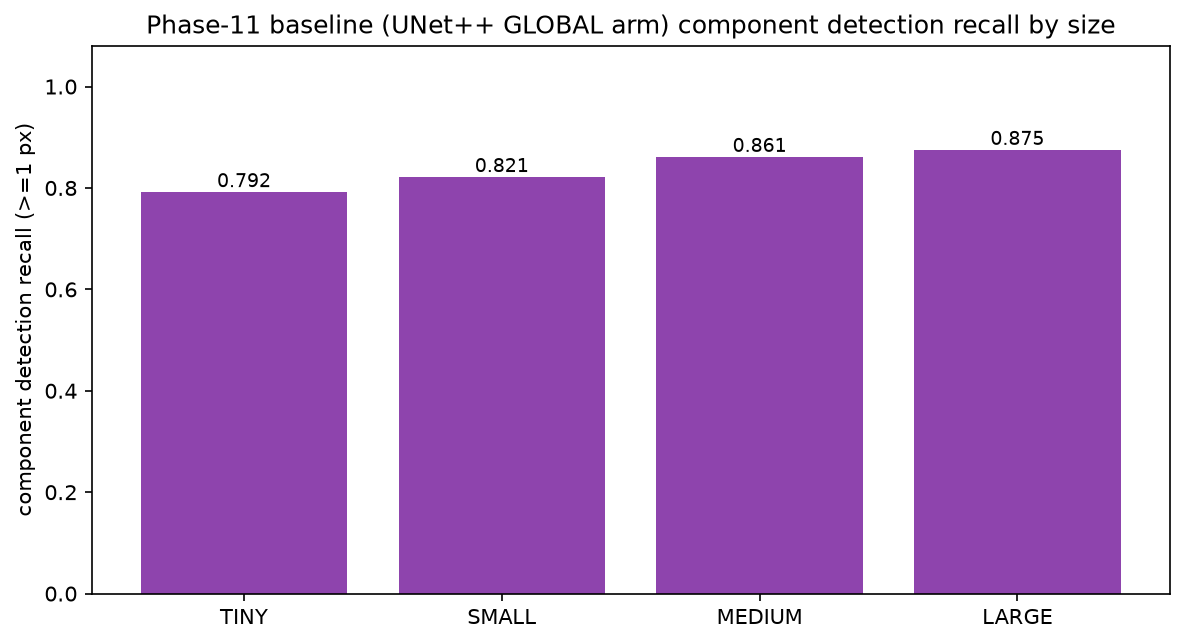

C:\Users\user\AppData\Local\Temp\ipykernel_32152\2158662141.py:68: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


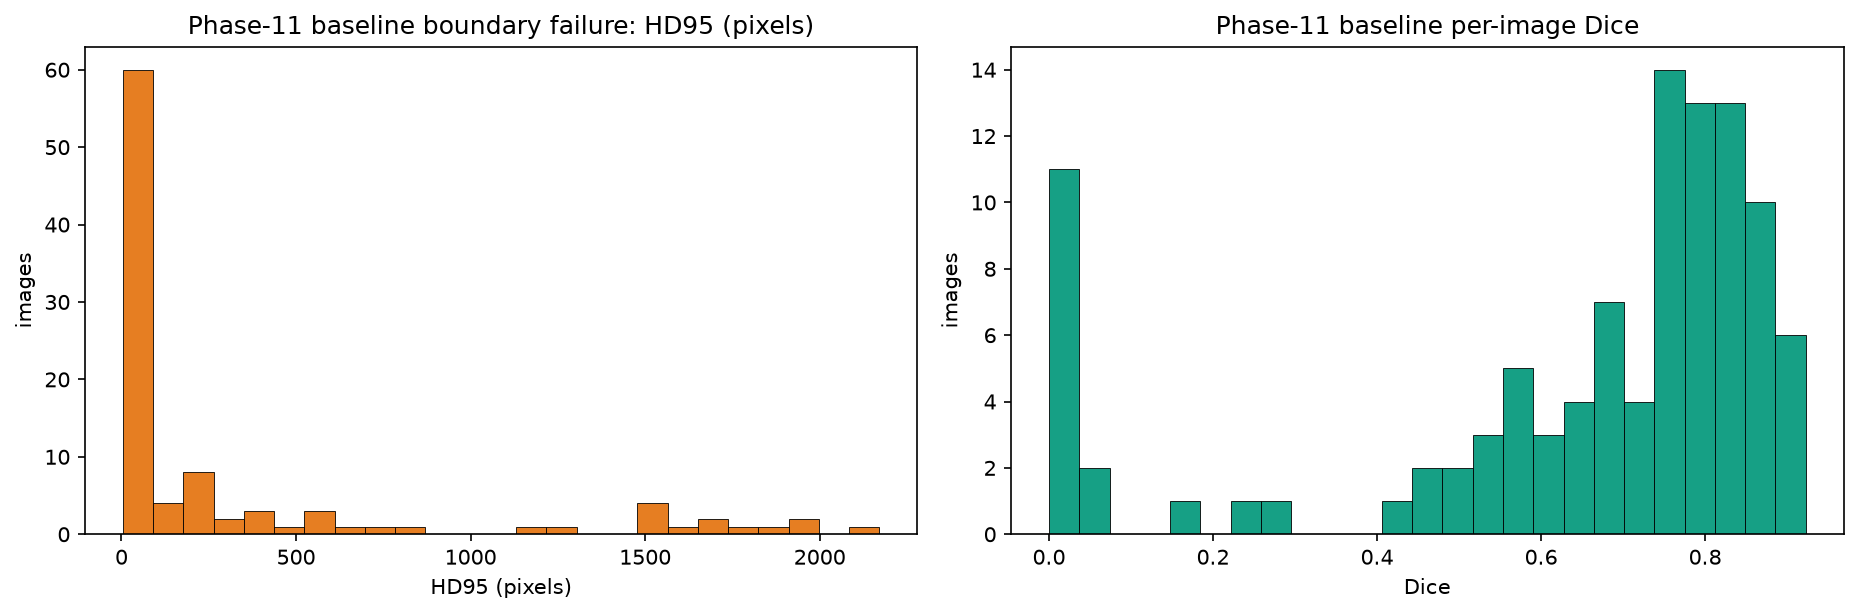

All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE


In [30]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

prov = [
    ('project_evaluation_component_recall_by_size.csv', _TAB / 'project_evaluation_component_recall_by_size.csv'),
    ('project_evaluation_coverage_sensitivity.csv', _TAB / 'project_evaluation_coverage_sensitivity.csv'),
    ('project_evaluation_per_component_metrics.csv', _TAB / 'project_evaluation_per_component_metrics.csv'),
]
_disp(_pd.DataFrame([{'artifact': n, 'sha256': _sha(p)[:16]} for n, p in prov if p.exists()]))

size = _pd.read_csv(_TAB / 'project_evaluation_component_recall_by_size.csv')
_disp(size[size['arm'] == 'GLOBAL'])
cov = _pd.read_csv(_TAB / 'project_evaluation_coverage_sensitivity.csv')
_disp(cov[cov['arm'] == 'GLOBAL'])

comp = _pd.read_csv(_TAB / 'project_evaluation_per_component_metrics.csv')
cg = comp[comp['arm'] == 'GLOBAL']
by = cg.groupby('size_stratum').agg(gt=('detection', 'size'), detected=('detection', 'sum')).reset_index()
by['missed'] = by['gt'] - by['detected']
by['recall'] = by['detected'] / by['gt']
by['metric_domain'] = 'OBJECT_COMPONENT_DETECTION'; by['label'] = LBL
_disp(by.round(6))

fig, ax = _plt.subplots(figsize=(8, 4.4))
order = ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
vals = [float(by[by['size_stratum'] == s]['recall'].iloc[0]) for s in order]
ax.bar(order, vals, color='#8e44ad')
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.08); ax.set_ylabel('component detection recall (>=1 px)')
ax.set_title('Phase-11 baseline (UNet++ GLOBAL arm) component detection recall by size')
_plt.tight_layout(); _p = _FIG / 'phase11_recall_by_size.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

pi = _pd.read_csv(_TAB / 'project_evaluation_per_image_metrics.csv')
gp = pi[pi['arm'] == 'GLOBAL']
hv = gp['hd95'].dropna().astype(float)
fig, (ax1, ax2) = _plt.subplots(1, 2, figsize=(12.5, 4.2))
ax1.hist(hv, bins=25, color='#e67e22', edgecolor='black', lw=0.4)
ax1.set_xlabel('HD95 (pixels)'); ax1.set_ylabel('images')
ax1.set_title('Phase-11 baseline boundary failure: HD95 (pixels)')
ax2.hist(gp['dice'].dropna().astype(float), bins=25, color='#16a085', edgecolor='black', lw=0.4)
ax2.set_xlabel('Dice'); ax2.set_ylabel('images'); ax2.set_title('Phase-11 baseline per-image Dice')
_plt.tight_layout(); _p = _FIG / 'phase11_boundary_and_dice.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('All values above are', LBL)